# DBA5101 - Final Report


## Imports, source file, and schema

In [143]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 30)
DATA_DIR = Path.cwd()  # Change only if the notebook kernel starts elsewhere.
from IPython.display import Markdown
from statistics import NormalDist
from math import erfc, sqrt
import gc

## 1. Exploratory Data Analysis (raw data: `Data-GP1-revised-final.csv`)

This section works directly off the **raw, uncleaned** source file.

**Note:** the dataframe built and used in this section (`eda`) is entirely separate from the `df_full` used later in modeling -- `df_full` is loaded fresh from `clean_records.csv` in Section 3, and nothing from this section feeds into it directly.

In [144]:
# Load the raw source file for EDA purposes only.
raw_candidates = sorted(DATA_DIR.glob("Data-GP1-revised-final.csv"))
if not raw_candidates:
    raise FileNotFoundError(f"Data-GP1-revised-final.csv not found in {DATA_DIR.resolve()}")
raw_path = raw_candidates[0]
print("Raw EDA source:", raw_path.resolve())

eda_raw = pd.read_csv(raw_path)
print("Raw shape:", eda_raw.shape)
display(eda_raw.head())

# ==== Construct purchase_date, dept_date, lead_days, dept_dow, dept_month ====
eda_raw["dept_date"] = pd.to_datetime(eda_raw["Dept_Date"], format="%m/%d/%y")
eda_raw["purchase_date"] = pd.to_datetime(eda_raw["Purchase_Date"], format="%m/%d/%y")

eda_raw["lead_days"] = (eda_raw["dept_date"] - eda_raw["purchase_date"]).dt.days
eda_raw["dept_dow"] = eda_raw["dept_date"].dt.dayofweek        # 0 = Monday ... 6 = Sunday
eda_raw["dept_month"] = eda_raw["dept_date"].dt.strftime("%Y-%m")

# Sanity checks -- always look at these before trusting downstream EDA
display(eda_raw[["purchase_date", "dept_date", "lead_days", "dept_dow", "dept_month"]].head())
print("lead_days range:", eda_raw["lead_days"].min(), "to", eda_raw["lead_days"].max())
print("negative lead_days (would indicate a parsing/logic error):", (eda_raw["lead_days"] < 0).sum())


Raw EDA source: C:\Users\aatmi\Downloads\Data-GP1-revised-final.csv
Raw shape: (209697, 9)


,num_seats_total,mean_net_ticket_price,Dept_Date,Purchase_Date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat
0,1,188.663422,10/9/19,10/10/18,A,1,0,0,A
1,1,358.428869,5/27/19,6/6/18,B,0,1,0,A
2,1,356.372684,5/31/20,6/17/19,B,0,1,0,A
3,1,396.370505,12/10/19,12/27/18,C,0,1,0,A
4,1,364.264552,5/31/20,6/19/19,B,0,1,0,A


,purchase_date,dept_date,lead_days,dept_dow,dept_month
0,2018-10-10,2019-10-09,364,2,2019-10
1,2018-06-06,2019-05-27,355,0,2019-05
2,2019-06-17,2020-05-31,349,6,2020-05
3,2018-12-27,2019-12-10,348,1,2019-12
4,2019-06-19,2020-05-31,347,6,2020-05


lead_days range: 0 to 364
negative lead_days (would indicate a parsing/logic error): 0


### 1.1.3 Price-quantity relationship
A simple bivariate plot of price against quantity, with no controls, to establish the naive/uncontrolled relationship before we discuss why it's confounded.

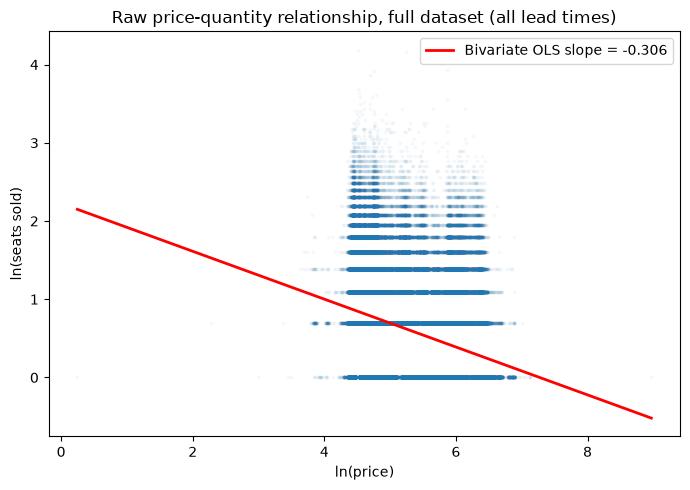

Naive (uncontrolled) log-log slope, full data: -0.306
Pearson correlation ln(P) vs ln(Q): -0.282


In [145]:
eda = eda_raw.copy()
eda["_ln_price"] = np.log(eda["mean_net_ticket_price"])
eda["_ln_seats"] = np.log(eda["num_seats_total"])

# ---- 1.1.3 Price-quantity relationship (raw, all lead times, no controls) ----
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(eda["_ln_price"], eda["_ln_seats"], s=3, alpha=0.03)
naive_slope, naive_intercept = np.polyfit(eda["_ln_price"], eda["_ln_seats"], 1)
xs = np.linspace(eda["_ln_price"].min(), eda["_ln_price"].max(), 50)
ax.plot(xs, naive_intercept + naive_slope * xs, color="red", linewidth=2,
        label=f"Bivariate OLS slope = {naive_slope:.3f}")
ax.set_xlabel("ln(price)")
ax.set_ylabel("ln(seats sold)")
ax.set_title("Raw price-quantity relationship, full dataset (all lead times)")
ax.legend()
plt.tight_layout()
plt.savefig("fig_113_price_quantity_raw.png", dpi=150)
plt.show()

print(f"Naive (uncontrolled) log-log slope, full data: {naive_slope:.3f}")
print(f"Pearson correlation ln(P) vs ln(Q): {eda[['_ln_price','_ln_seats']].corr().iloc[0,1]:.3f}")


### 1.1.4 Booking timing
Here we bin into simple 10-day windows purely to visualize the raw pattern across the full range of observed lead times.

,bin_start,n,mean_price,mean_seats
0,0,35519,403.790327,2.079507
1,10,30656,319.134025,1.839151
2,20,21567,255.560174,1.899986
3,30,17158,200.066098,2.217508
4,40,14341,183.751453,2.301095
...,...,...,...,...
31,310,225,144.992572,2.488889
32,320,216,133.881590,2.671296
33,330,163,150.793682,3.128834
34,340,211,149.416572,2.165877


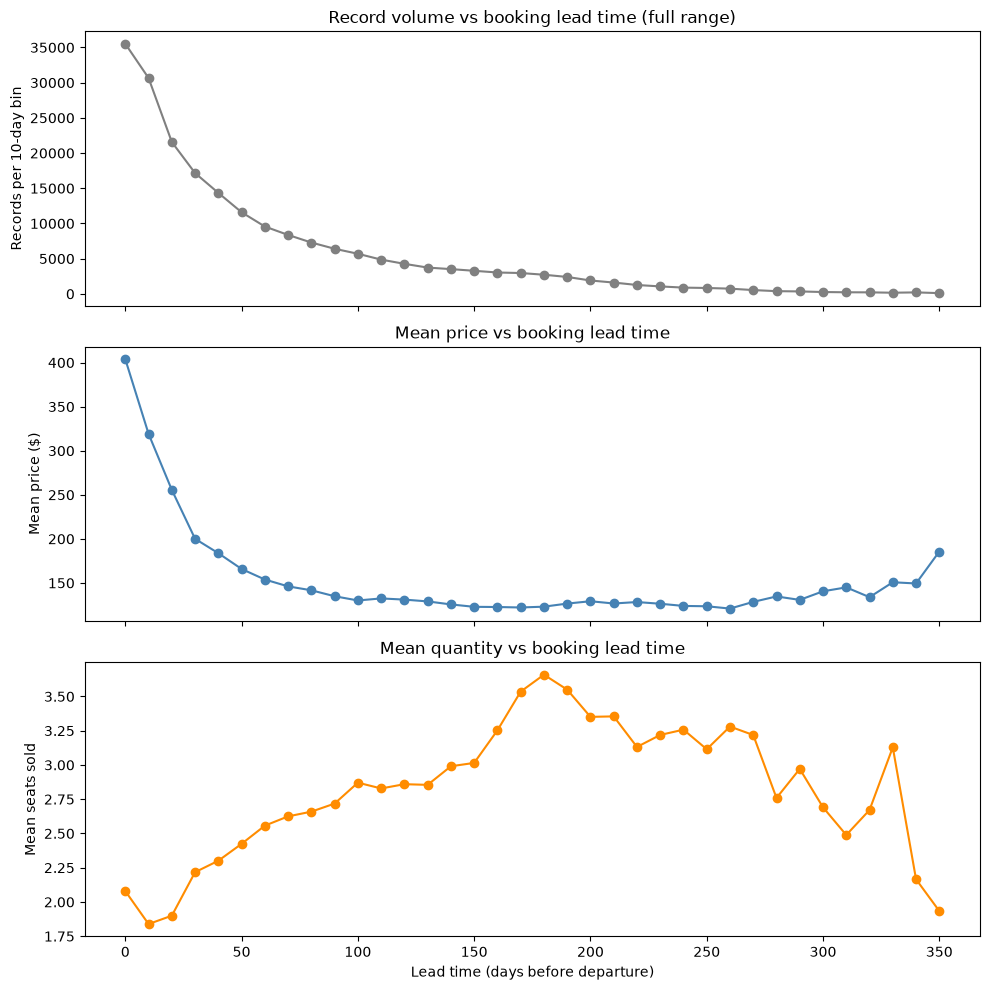

In [146]:
# ---- 1.1.4 Booking timing: raw pattern across the FULL lead-time range ----
day_bins = pd.cut(eda["lead_days"], bins=list(range(0, 370, 10)), right=False)
by_bin = eda.groupby(day_bins, observed=True).agg(
    n=("num_seats_total", "size"),
    mean_price=("mean_net_ticket_price", "mean"),
    mean_seats=("num_seats_total", "mean"),
).reset_index()
by_bin["bin_start"] = by_bin["lead_days"].apply(lambda iv: iv.left)
display(by_bin[["bin_start", "n", "mean_price", "mean_seats"]])

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
axes[0].plot(by_bin["bin_start"], by_bin["n"], marker="o", color="gray")
axes[0].set_ylabel("Records per 10-day bin")
axes[0].set_title("Record volume vs booking lead time (full range)")
axes[1].plot(by_bin["bin_start"], by_bin["mean_price"], marker="o", color="steelblue")
axes[1].set_ylabel("Mean price ($)")
axes[1].set_title("Mean price vs booking lead time")
axes[2].plot(by_bin["bin_start"], by_bin["mean_seats"], marker="o", color="darkorange")
axes[2].set_ylabel("Mean seats sold")
axes[2].set_xlabel("Lead time (days before departure)")
axes[2].set_title("Mean quantity vs booking lead time")
plt.tight_layout()
plt.savefig("fig_114_leadtime_full_range.png", dpi=150)
plt.show()


### 1.1.5 Heterogeneity across trains, cabins, customer categories, and calendar time
These plots motivate including train fixed effects, cabin type, customer category, and month/day-of-week indicators as controls.

,Train_Number_All,mean_price,mean_seats,n_records
4,E,199.667665,2.803476,26297
7,H,202.542874,2.608826,19306
1,B,204.505029,2.775610,26855
6,G,211.245763,2.564438,23030
5,F,220.968886,2.495554,18557
8,I,221.625445,2.301917,17836
12,M,224.557086,1.856099,9583
9,J,233.166940,2.111555,13016
3,D,239.963447,2.143030,13235
0,A,240.999079,2.055828,12019


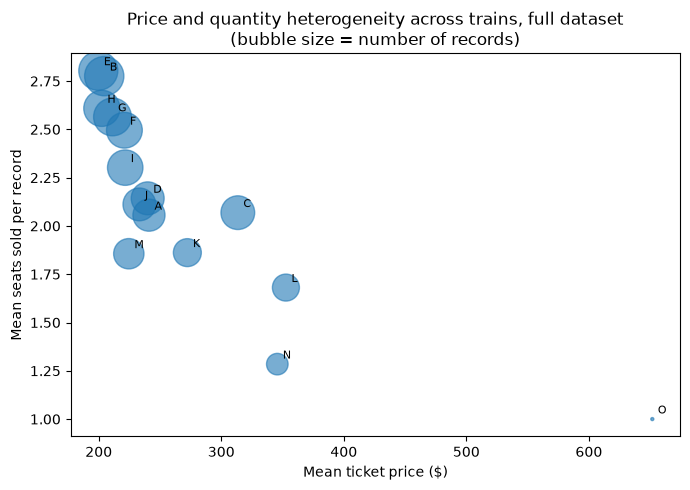

In [147]:
# ---- 1.1.5a Heterogeneity across trains ----
train_summary = eda.groupby("Train_Number_All", observed=True).agg(
    mean_price=("mean_net_ticket_price", "mean"),
    mean_seats=("num_seats_total", "mean"),
    n_records=("num_seats_total", "size"),
).reset_index().sort_values("mean_price")
display(train_summary)

fig, ax = plt.subplots(figsize=(7, 5))
sizes = 800 * (train_summary["n_records"] / train_summary["n_records"].max()) ** 0.5
ax.scatter(train_summary["mean_price"], train_summary["mean_seats"], s=sizes, alpha=0.6)
for _, r in train_summary.iterrows():
    ax.annotate(str(r["Train_Number_All"]), (r["mean_price"], r["mean_seats"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Mean ticket price ($)")
ax.set_ylabel("Mean seats sold per record")
ax.set_title("Price and quantity heterogeneity across trains, full dataset\n(bubble size = number of records)")
plt.tight_layout()
plt.savefig("fig_115a_train_raw.png", dpi=150)
plt.show()


,isNormCabin,mean_price,mean_seats,n_records,cabin
0,0,357.722110,1.953683,84246,Special cabin
1,1,144.424251,2.671338,125451,Normal cabin


,Customer_Cat,mean_price,mean_seats,n_records
0,A,355.826540,1.526505,47293
1,B,193.509513,2.632441,162404


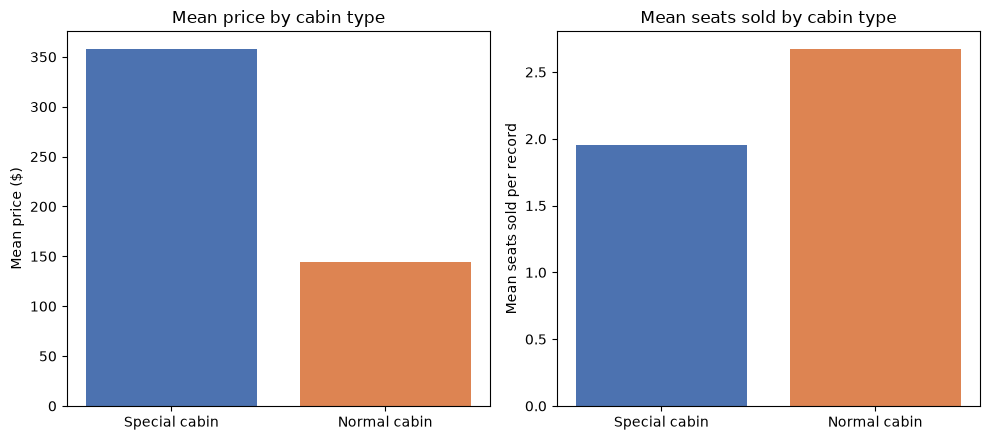

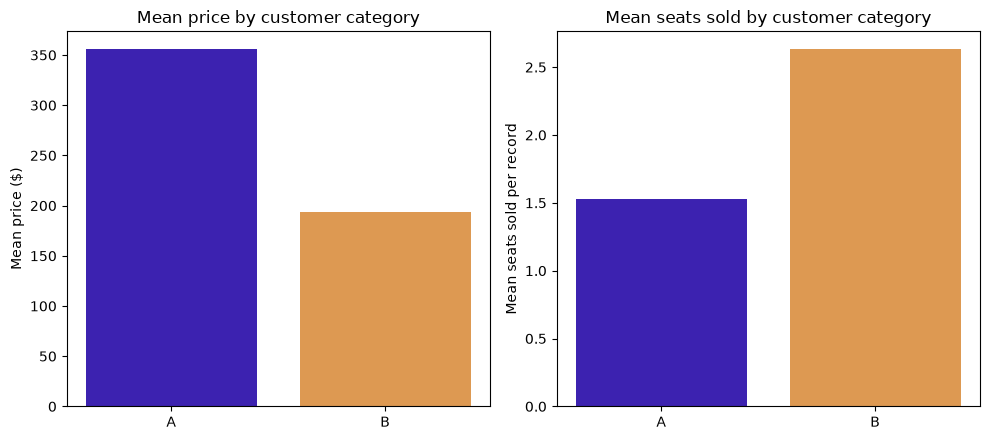

In [148]:
# ---- 1.1.5b Cabin type ----
cabin_summary = eda.groupby("isNormCabin", observed=True).agg(
    mean_price=("mean_net_ticket_price", "mean"),
    mean_seats=("num_seats_total", "mean"),
    n_records=("num_seats_total", "size"),
).reset_index()
cabin_summary["cabin"] = cabin_summary["isNormCabin"].map({1: "Normal cabin", 0: "Special cabin"})
display(cabin_summary)

cust_summary = eda.groupby("Customer_Cat", observed=True).agg(
    mean_price=("mean_net_ticket_price", "mean"),
    mean_seats=("num_seats_total", "mean"),
    n_records=("num_seats_total", "size"),
).reset_index()
display(cust_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].bar(cabin_summary["cabin"], cabin_summary["mean_price"], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Mean price by cabin type"); axes[0].set_ylabel("Mean price ($)")
axes[1].bar(cabin_summary["cabin"], cabin_summary["mean_seats"], color=["#4C72B0", "#DD8452"])
axes[1].set_title("Mean seats sold by cabin type"); axes[1].set_ylabel("Mean seats sold per record")
plt.tight_layout()
plt.savefig("fig_115b_cabin_raw.png", dpi=150)
plt.show()

# ---- 1.1.5c Customer category ----
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].bar(cust_summary["Customer_Cat"], cust_summary["mean_price"], color=["#3C22B0", "#DD9952"])
axes[0].set_title("Mean price by customer category"); axes[0].set_ylabel("Mean price ($)")
axes[1].bar(cust_summary["Customer_Cat"], cust_summary["mean_seats"], color=["#3C22B0", "#DD9952"])
axes[1].set_title("Mean seats sold by customer category"); axes[1].set_ylabel("Mean seats sold per record")
plt.tight_layout()
plt.savefig("fig_115c_customer_raw.png", dpi=150)
plt.show()


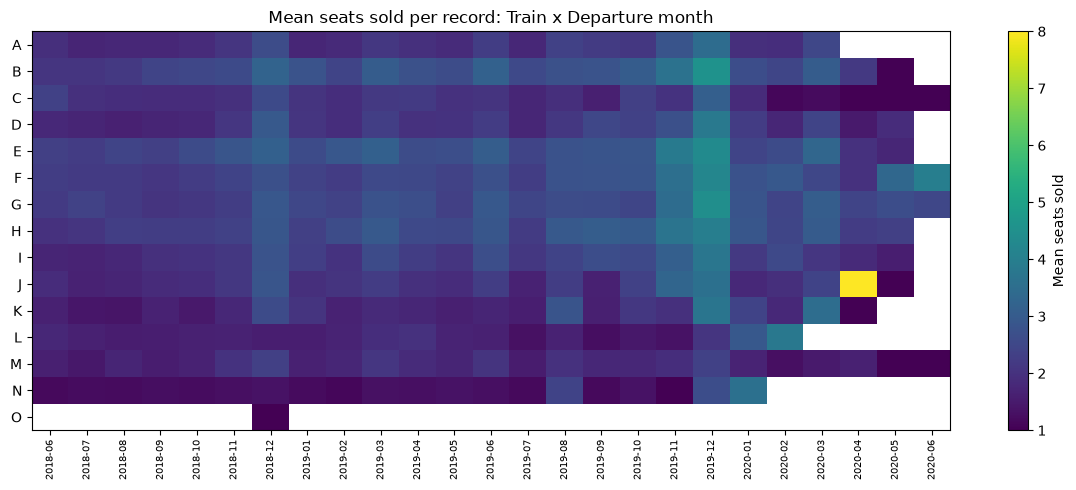

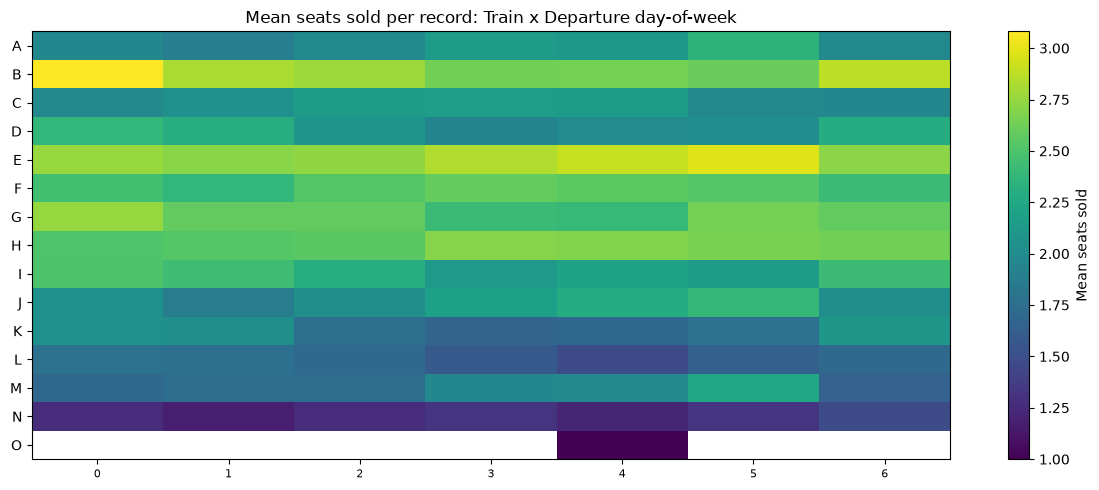

In [149]:
# ---- 1.1.5d Seasonality heatmap (train x departure month) ----
pivot_month = eda.pivot_table(index="Train_Number_All", columns="dept_month",
                               values="num_seats_total", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(pivot_month.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(pivot_month.index))); ax.set_yticklabels(pivot_month.index)
ax.set_xticks(range(len(pivot_month.columns))); ax.set_xticklabels(pivot_month.columns, rotation=90, fontsize=7)
ax.set_title("Mean seats sold per record: Train x Departure month")
plt.colorbar(im, ax=ax, label="Mean seats sold")
plt.tight_layout()
plt.savefig("fig_115d_heatmap_train_month.png", dpi=150)
plt.show()

# ---- 1.1.5e Seasonality heatmap (train x day-of-week) ----
pivot_dow = eda.pivot_table(index="Train_Number_All", columns="dept_dow",
                             values="num_seats_total", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(pivot_dow.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(pivot_dow.index))); ax.set_yticklabels(pivot_dow.index)
ax.set_xticks(range(len(pivot_dow.columns))); ax.set_xticklabels(pivot_dow.columns, rotation=0, fontsize=8)
ax.set_title("Mean seats sold per record: Train x Departure day-of-week")
plt.colorbar(im, ax=ax, label="Mean seats sold")
plt.tight_layout()
plt.savefig("fig_115e_heatmap_train_dow.png", dpi=150)
plt.show()


## 2. Sample and variable construction (rationale)

**Why a 120-day lead-time window:** Section 1.1.4 shows booking volume declining by roughly 90% between the 0-9 day and 120-129 day windows, and average price stabilizing and then becoming increasingly noisy beyond ~120 days as bin sizes shrink into the low hundreds of records. We restrict the estimation sample to bookings made within 120 days of departure, where we have a dense and stable evidence base, rather than force-fitting the thinner, noisier long-horizon tail.

**Why 5 lead-time buckets (0-2, 3-7, 8-14, 15-30, >30 days):** the boundaries follow the break points visible in Section 1.1.4's price curve -- price falls fastest in the first two weeks before departure and then flattens -- treated as the practically meaningful stages of the pricing curve within the 120-day window, rather than imposing one continuous functional form on a relationship that is visibly not smooth.

**Why train, cabin, customer-category, month, and day-of-week controls:** Section 1.1.5 shows clear, persistent differences in average price and quantity across trains, cabin types, customer categories, and calendar time (both month and day-of-week), motivating train fixed effects plus these categorical controls in every model specification below.

## 3. Data cleaning pipeline: `Data-GP1-revised-final.csv` -> `clean_records.csv`



In [150]:


from __future__ import annotations

import re
import numpy as np

# ---------------------------------------------------------------------------
# Facts about the raw file, asserted at run time
# ---------------------------------------------------------------------------
RAW_NROWS = 209_697
RAW_COLS = [
    "num_seats_total", "mean_net_ticket_price", "Dept_Date", "Purchase_Date",
    "Train_Number_All", "isNormCabin", "isReturn", "isOneway", "Customer_Cat",
]

# Date format. Verified three ways (see the date-parsing step below):
#   (1) 60.8% / 60.3% of rows have a second component > 12, impossible under d/m/y
#   (2) "%d/%m/%y" fails on 127,497 / 126,471 rows and yields 9,397 negative lead times
#   (3) "%m/%d/%y" parses every row with zero negative lead times
DATE_FMT = "%m/%d/%y"

# Sampling frame: the file is every ticket SOLD inside this purchase window, while
# departures run to June 2020. This asymmetry is what truncates the booking curves.
PURCHASE_START = pd.Timestamp("2018-06-01")
PURCHASE_END = pd.Timestamp("2019-06-30")
total_records = len(eda_raw)  # full raw dataset, all 209,697 rows

candidate_L = [60, 90, 120, 180, 240]
rows = []
for L in candidate_L:
    start = PURCHASE_START + pd.Timedelta(days=L)
    # Same eligibility logic as the cleaning pipeline's in_analysis_sample, just
    # parameterized by L instead of hardcoded at 120.
    mask = (
        (eda_raw["dept_date"] >= start)
        & (eda_raw["dept_date"] <= PURCHASE_END)
        & (eda_raw["lead_days"] <= L)
    )
    sub = eda_raw.loc[mask]

    # "Booking curve covered": the % of ALL raw bookings (regardless of departure
    # eligibility) that occur within L days of departure. This answers "if we only
    # ever look at the last L days before departure, what share of real bookings
    # are we capturing?" -- independent of the sample-eligibility question above.
    coverage = (eda_raw["lead_days"] <= L).mean()

    rows.append({
        "L*": L,
        "Departure dates": sub["dept_date"].nunique(),
        "Span from": start.date(),
        "Records": len(sub),
        "Booking curve covered": f"{coverage:.1%}",
    })

sensitivity_table = pd.DataFrame(rows)
display(sensitivity_table)

# ---------------------------------------------------------------------------
# Judgement calls, all in one place
# ---------------------------------------------------------------------------
# Analysis sample: .
LEAD_WINDOW = 120

# Booking-stage controls: advance-purchase tiers used by the demand model.
LEAD_BINS = [-1, 2, 7, 14, 30, np.inf]
LEAD_LABELS = ["0-2", "3-7", "8-14", "15-30", ">30"]

# Outlier flags. Nothing is dropped; these only mark rows.
PRICE_HI_Q = 0.999          # about 888
PRICE_LO_Q = 0.001          # about 70
PRICE_ABSURD = 3000.0       # natural break: 7855.77 is 4.6x the next largest fare
PARTY_LARGE = 20            # seats per record
RARE_TRAIN_MIN_N = 10       # train O appears once

# Excel silently rewrites "10/9/19" as "2010/9/19" whenever the day component is <= 12,
# which once damaged about 39% of both date columns. This guard is harmless on a clean
# file and corrective on a damaged one, so the pipeline stays idempotent.
_EXCEL_DAMAGE = re.compile(r"^((?:19|20)(\d{2}))/(\d{1,2})/(\d{1,2})$")


def _repair_excel_dates(s: pd.Series) -> tuple[pd.Series, int]:
    hit = s.str.match(_EXCEL_DAMAGE, na=False)
    n = int(hit.sum())
    if n:
        s = s.mask(hit, s.str.replace(
            _EXCEL_DAMAGE, lambda m: f"{int(m.group(2))}/{m.group(3)}/{m.group(4)}",
            regex=True))
    return s, n


def load_raw(path: str | Path) -> pd.DataFrame:
    """Read the source file with explicit dtypes and without inventing missing values."""
    df = pd.read_csv(
        path,
        dtype={
            "num_seats_total": "int64", "mean_net_ticket_price": "float64",
            "Dept_Date": "string", "Purchase_Date": "string",
            "Train_Number_All": "string", "isNormCabin": "int64",
            "isReturn": "int64", "isOneway": "int64", "Customer_Cat": "string",
        },
        keep_default_na=False,
        na_values=[],          # the file has no NA tokens; do not create any
    )
    for c in ("Dept_Date", "Purchase_Date"):
        df[c], n = _repair_excel_dates(df[c])
        if n:
            print(f"WARNING: repaired {n:,} Excel-damaged dates in {c}")
    return df


def clean(path: str | Path) -> pd.DataFrame:
    """Return the record-level cleaned table. Same number of rows as the input."""
    df = load_raw(path)
    assert list(df.columns) == RAW_COLS, f"unexpected columns: {list(df.columns)}"
    assert len(df) == RAW_NROWS, f"expected {RAW_NROWS} rows, got {len(df)}"
    n_in = len(df)
    assert sum((df[c].astype("string").str.strip() == "").sum() for c in df.columns) == 0

    # --- dates: the highest-risk step, so the rejected format is re-tested ---
    df["dept_date"] = pd.to_datetime(df["Dept_Date"], format=DATE_FMT, errors="raise")
    df["purchase_date"] = pd.to_datetime(df["Purchase_Date"], format=DATE_FMT, errors="raise")
    alt_d = pd.to_datetime(df["Dept_Date"], format="%d/%m/%y", errors="coerce")
    alt_p = pd.to_datetime(df["Purchase_Date"], format="%d/%m/%y", errors="coerce")
    alt_negative = int(((alt_d - alt_p).dt.days < 0).sum())
    assert alt_d.isna().sum() > 100_000 and alt_negative > 0, \
        "the day/month/year reading should fail; the format proof is broken"

    # --- lead time and domain checks ---
    df["lead_days"] = (df["dept_date"] - df["purchase_date"]).dt.days
    assert df["lead_days"].min() >= 0, "a purchase is dated after its own departure"
    for c in ("isNormCabin", "isReturn", "isOneway"):
        assert set(df[c].unique()) <= {0, 1}, f"{c} is not a 0/1 indicator"
    assert (df["num_seats_total"] >= 1).all() and (df["mean_net_ticket_price"] > 0).all()

    # --- duplicates: audited, never removed ---
    # A record is a semi-aggregated group of seats sold at one fare. Records are NOT
    # unique on the observed attributes: 3,407 combinations repeat at different fares
    # (median gap 77), which is the only visible trace of unobserved fare classes and
    # the reason price carries measurement error.
    cell_key = ["dept_date", "purchase_date", "Train_Number_All", "isNormCabin",
                "isReturn", "isOneway", "Customer_Cat"]
    df["cell_n_records"] = df.groupby(cell_key, observed=True)["mean_net_ticket_price"].transform("size")

    # --- outliers: flagged, never dropped (together under 1% of seats) ---
    df["flag_price_hi"] = df["mean_net_ticket_price"] > df["mean_net_ticket_price"].quantile(PRICE_HI_Q)
    df["flag_price_lo"] = df["mean_net_ticket_price"] < df["mean_net_ticket_price"].quantile(PRICE_LO_Q)
    df["flag_price_absurd"] = df["mean_net_ticket_price"] > PRICE_ABSURD
    df["flag_party_large"] = df["num_seats_total"] >= PARTY_LARGE
    df["flag_rare_train"] = df["Train_Number_All"].map(
        df["Train_Number_All"].value_counts()) < RARE_TRAIN_MIN_N

    # --- the analysis sample (the decision the estimates rest on) ---
    # Departures before PURCHASE_START + L are missing their early, cheap bookings and
    # departures after PURCHASE_END are missing their late, expensive ones. Left alone,
    # that alone swings the mean observed fare across departure months by 4.2x.
    start = PURCHASE_START + pd.Timedelta(days=LEAD_WINDOW)
    df["in_analysis_sample"] = (
        (df["dept_date"] >= start)
        & (df["dept_date"] <= PURCHASE_END)
        & (df["lead_days"] <= LEAD_WINDOW)
    )

    # --- columns the demand model consumes ---
    df["lead_cat"] = pd.cut(df["lead_days"], LEAD_BINS, labels=LEAD_LABELS)
    df["dept_dow"] = df["dept_date"].dt.dayofweek                     # 0 = Monday
    df["dept_month"] = df["dept_date"].dt.to_period("M").astype(str)  # departure year-month
    df["revenue"] = df["num_seats_total"] * df["mean_net_ticket_price"]
    df["ln_Q"] = np.log(df["num_seats_total"])
    df["ln_P"] = np.log(df["mean_net_ticket_price"])

    assert len(df) == n_in, f"row count not preserved: {n_in} -> {len(df)}"
    return df


def summarise(df: pd.DataFrame) -> None:
    s = df[df["in_analysis_sample"]]
    print(f"rows in / out          : {len(df):,} / {len(df):,}")
    print(f"lead_days              : [{df.lead_days.min()}, {df.lead_days.max()}], "
          f"median {df.lead_days.median():.0f}")
    print(f"repeated attribute sets: {int((df.cell_n_records > 1).sum()):,} rows "
          f"in {df.loc[df.cell_n_records > 1].groupby(['dept_date','purchase_date','Train_Number_All','isNormCabin','isReturn','isOneway','Customer_Cat'], observed=True).ngroups:,} groups")
    print(f"flagged (any)          : {int(df[[c for c in df if c.startswith('flag_')]].any(axis=1).sum()):,} rows")
    print(f"analysis sample        : {len(s):,} rows ({len(s)/len(df):.1%}), "
          f"{s.dept_date.nunique()} departure dates, "
          f"{s.dept_date.min().date()} to {s.dept_date.max().date()}")
    swing = df.groupby("dept_month").mean_net_ticket_price.mean()
    swing_s = s.groupby("dept_month").mean_net_ticket_price.mean()
    print(f"mean fare swing across departure months: "
          f"{swing.max()/swing.min():.2f}x full file, {swing_s.max()/swing_s.min():.2f}x analysis sample")


# ---------------------------------------------------------------------------
# Run the pipeline on the raw file and write clean_records.csv for Section 4
# ---------------------------------------------------------------------------
raw_source = DATA_DIR / "Data-GP1-revised-final.csv"
clean_records_df = clean(raw_source)
summarise(clean_records_df)

clean_out_path = DATA_DIR / "clean_records.csv"
clean_records_df.to_csv(clean_out_path, index=False)
print(f"written: {clean_out_path.resolve()}")


,L*,Departure dates,Span from,Records,Booking curve covered
0,60,335,2018-07-31,113042,62.9%
1,90,305,2018-08-30,124570,74.7%
2,120,275,2018-09-29,123991,82.7%
3,180,215,2018-11-28,106626,92.6%
4,240,155,2019-01-27,79660,97.7%


rows in / out          : 209,697 / 209,697
lead_days              : [0, 364], median 39
repeated attribute sets: 6,831 rows in 3,407 groups
flagged (any)          : 559 rows
analysis sample        : 123,991 rows (59.1%), 275 departure dates, 2018-09-29 to 2019-06-30
mean fare swing across departure months: 4.18x full file, 1.36x analysis sample
written: C:\Users\aatmi\Downloads\clean_records.csv


## 4. Modeling pipeline (uses `clean_records.csv`)

In [151]:
candidates = sorted(DATA_DIR.glob("clean_records*.csv"),
                    key=lambda p: (p.stat().st_mtime_ns, p.name), reverse=True)
if not candidates:
    raise FileNotFoundError(f"No clean_records*.csv found in {DATA_DIR.resolve()}")
display(pd.DataFrame({"file": [p.name for p in candidates],
                      "modified": [pd.Timestamp(p.stat().st_mtime, unit="s") for p in candidates]}))
data_path = candidates[0]
print("Selected:", data_path.resolve())
header = pd.read_csv(data_path, nrows=0)
identifier_types = {c: str for c in ["Train_Number_All", "Customer_Cat"] if c in header}
df_loaded = pd.read_csv(data_path, dtype=identifier_types, float_precision="round_trip")
df_full = df_loaded.copy(deep=True)
original_full_N = len(df_full)
print("Dataset shape:", df_full.shape)
print("Column names:", df_full.columns.tolist())
display(df_full.head())

,file,modified
0,clean_records.csv,2026-09-12 10:16:38.179393530


Selected: C:\Users\aatmi\Downloads\clean_records.csv
Dataset shape: (209697, 25)
Column names: ['num_seats_total', 'mean_net_ticket_price', 'Dept_Date', 'Purchase_Date', 'Train_Number_All', 'isNormCabin', 'isReturn', 'isOneway', 'Customer_Cat', 'dept_date', 'purchase_date', 'lead_days', 'cell_n_records', 'flag_price_hi', 'flag_price_lo', 'flag_price_absurd', 'flag_party_large', 'flag_rare_train', 'in_analysis_sample', 'lead_cat', 'dept_dow', 'dept_month', 'revenue', 'ln_Q', 'ln_P']


,num_seats_total,mean_net_ticket_price,Dept_Date,Purchase_Date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,dept_date,purchase_date,lead_days,cell_n_records,flag_price_hi,flag_price_lo,flag_price_absurd,flag_party_large,flag_rare_train,in_analysis_sample,lead_cat,dept_dow,dept_month,revenue,ln_Q,ln_P
0,1,188.663422,10/9/19,10/10/18,A,1,0,0,A,2019-10-09,2018-10-10,364,1,False,False,False,False,False,False,>30,2,2019-10,188.663422,0.0,5.239965
1,1,358.428869,5/27/19,6/6/18,B,0,1,0,A,2019-05-27,2018-06-06,355,1,False,False,False,False,False,False,>30,0,2019-05,358.428869,0.0,5.881730
2,1,356.372684,5/31/20,6/17/19,B,0,1,0,A,2020-05-31,2019-06-17,349,1,False,False,False,False,False,False,>30,6,2020-05,356.372684,0.0,5.875977
3,1,396.370505,12/10/19,12/27/18,C,0,1,0,A,2019-12-10,2018-12-27,348,1,False,False,False,False,False,False,>30,1,2019-12,396.370505,0.0,5.982349
4,1,364.264552,5/31/20,6/19/19,B,0,1,0,A,2020-05-31,2019-06-19,347,1,False,False,False,False,False,False,>30,6,2020-05,364.264552,0.0,5.897880


In [152]:
required = ["num_seats_total", "mean_net_ticket_price", "purchase_date", "dept_date",
            "Train_Number_All", "isNormCabin", "isReturn", "isOneway", "Customer_Cat",
            "lead_days", "dept_dow", "dept_month", "in_analysis_sample"]
missing_columns = [c for c in required if c not in df_full]
print("Missing required columns:", missing_columns)
if missing_columns or df_full.empty:
    raise ValueError("Need a nonempty cleaned transaction file with every required column.")
df_full["_source_row"] = np.arange(len(df_full)) + 2

Missing required columns: []


## Validate cleaned dates and calendar variables
Read only cleaned ISO `purchase_date` / `dept_date` with `%Y-%m-%d`. Preserve the supplied `lead_days`, `dept_dow`, and year-month `dept_month`. Display mismatches and **stop** rather than replacing inconsistent values. Missing/unparseable modelling values are audited explicitly before exclusion.

In [153]:
for col in ["purchase_date", "dept_date"]:
    original = df_full[col].copy()
    parsed = pd.to_datetime(original, format="%Y-%m-%d", errors="coerce")
    print(col, "- cleaned ISO / parsed examples:")
    display(pd.DataFrame({"cleaned ISO": original, "parsed": parsed}).head(10))
    failed = original.notna() & parsed.isna()
    print("Unparseable nonmissing cleaned dates:", int(failed.sum()))
    if failed.any():
        with pd.option_context("display.max_rows", None):
            display(df_full.loc[failed, ["_source_row", col]])
    df_full[col] = parsed

for col in ["num_seats_total", "mean_net_ticket_price", "lead_days", "dept_dow"]:
    numeric = pd.to_numeric(df_full[col], errors="coerce")
    failed = df_full[col].notna() & numeric.isna()
    print(col, "— nonnumeric values:", int(failed.sum()))
    if failed.any():
        display(df_full.loc[failed, ["_source_row", col]])
    df_full[col] = numeric

for col in ["Train_Number_All", "isNormCabin", "isReturn", "isOneway", "Customer_Cat"]:
    # Blank labels are missing; retain all other observed labels without recoding.
    df_full[col] = df_full[col].replace(r"^\s*$", np.nan, regex=True)

# Preserve the cleaned year-month labels; blank labels count as missing.
df_full["dept_month"] = df_full["dept_month"].replace(r"^\s*$", np.nan, regex=True)

purchase_date - cleaned ISO / parsed examples:


,cleaned ISO,parsed
0,2018-10-10,2018-10-10
1,2018-06-06,2018-06-06
2,2019-06-17,2019-06-17
3,2018-12-27,2018-12-27
4,2019-06-19,2019-06-19
5,2019-06-20,2019-06-20
6,2018-06-20,2018-06-20
7,2018-11-15,2018-11-15
8,2018-11-15,2018-11-15
9,2018-09-13,2018-09-13


Unparseable nonmissing cleaned dates: 0
dept_date - cleaned ISO / parsed examples:


,cleaned ISO,parsed
0,2019-10-09,2019-10-09
1,2019-05-27,2019-05-27
2,2020-05-31,2020-05-31
3,2019-12-10,2019-12-10
4,2020-05-31,2020-05-31
5,2020-05-23,2020-05-23
6,2019-05-23,2019-05-23
7,2019-10-18,2019-10-18
8,2019-10-14,2019-10-14
9,2019-08-12,2019-08-12


Unparseable nonmissing cleaned dates: 0
num_seats_total — nonnumeric values: 0
mean_net_ticket_price — nonnumeric values: 0
lead_days — nonnumeric values: 0
dept_dow — nonnumeric values: 0


In [154]:
recomputed_lead = (df_full["dept_date"] - df_full["purchase_date"]).dt.days
validation_values = {
    "lead_days": recomputed_lead,
    "dept_dow": df_full["dept_date"].dt.dayofweek,
    "dept_month": df_full["dept_date"].dt.strftime("%Y-%m"),
}
validation_rows = []
mismatch_total = 0
for col, expected in validation_values.items():
    supplied = df_full[col]
    comparable = supplied.notna() & expected.notna()
    mismatch = comparable & supplied.ne(expected)
    validation_rows.append({"Variable": col, "Values compared": int(comparable.sum()),
                            "Mismatches": int(mismatch.sum()),
                            "Not comparable": int((~comparable).sum())})
    mismatch_total += int(mismatch.sum())
    if mismatch.any():
        print("Mismatched cleaned values:", col)
        audit = df_full.loc[mismatch, ["_source_row", "purchase_date", "dept_date", col]].copy()
        audit["expected_from_cleaned_dates"] = expected.loc[mismatch]
        with pd.option_context("display.max_rows", None):
            display(audit)
display(pd.DataFrame(validation_rows))
if mismatch_total:
    raise ValueError("Cleaned date/lead/calendar validation failed. Inspect the displayed mismatches; "
                     "no supplied values have been replaced. Stop here and correct the source inconsistency.")

for col in ["dept_dow", "dept_month"]:
    df_full[col] = df_full[col].astype("category")

print("purchase_date range:", df_full["purchase_date"].min(), df_full["purchase_date"].max())
print("dept_date range:", df_full["dept_date"].min(), df_full["dept_date"].max())
display(df_full["lead_days"].agg(["min", "median", "max"]))
print("Unique trains:", df_full["Train_Number_All"].nunique(dropna=True))
display(df_full["Customer_Cat"].value_counts(dropna=False))
display(df_full[required].isna().sum().rename("missing"))
negative_lead = df_full["lead_days"].lt(0)
print("Negative cleaned lead times (reported, not filtered):", int(negative_lead.sum()))
display(df_full.loc[negative_lead, ["_source_row", "purchase_date", "dept_date", "lead_days"]])

,Variable,Values compared,Mismatches,Not comparable
0,lead_days,209697,0,0
1,dept_dow,209697,0,0
2,dept_month,209697,0,0


purchase_date range: 2018-06-01 00:00:00 2019-06-30 00:00:00
dept_date range: 2018-06-01 00:00:00 2020-06-13 00:00:00


min         0.0
median     39.0
max       364.0
Name: lead_days, dtype: float64

Unique trains: 15


Customer_Cat
B    162404
A     47293
Name: count, dtype: int64

num_seats_total          0
mean_net_ticket_price    0
purchase_date            0
dept_date                0
Train_Number_All         0
isNormCabin              0
isReturn                 0
isOneway                 0
Customer_Cat             0
lead_days                0
dept_dow                 0
dept_month               0
in_analysis_sample       0
Name: missing, dtype: int64

Negative cleaned lead times (reported, not filtered): 0


,_source_row,purchase_date,dept_date,lead_days


## Select the supplied 120-day sample and audit eligibility
Select **only `in_analysis_sample == True`**, using the existing cleaned flag rather than substituting a new horizon filter. Report missing flags; unrecognized nonmissing encodings stop selection. The lead-range check validates the supplied flag, not an additional silent exclusion.

Within the selected sample, apply the same common eligibility requirements as the preceding notebook: required modelling values must be present, price and seats must be finite and positive. Nonpositive seats are unsuitable both for log quantity and for seat-weighted price construction. Every excluded selected record is displayed with its reasons. Quality flags do not enter eligibility.

In [155]:
def read_boolean_flag(series, name):
    normalized = series.astype("string").str.strip().str.lower()
    true_values = ["true", "1", "1.0", "yes"]
    false_values = ["false", "0", "0.0", "no"]
    unknown = normalized.notna() & ~normalized.isin(true_values + false_values)
    if unknown.any():
        display(series.loc[unknown].rename(name))
        raise ValueError(f"Unrecognized {name} values; inspect before proceeding.")
    return normalized.isin(true_values), normalized.isna()

sample_true, sample_missing = read_boolean_flag(df_full["in_analysis_sample"], "in_analysis_sample")
df_selected = df_full.loc[sample_true].copy()
display(pd.Series({"Full cleaned source N": len(df_full), "Flagged 120-day source N": len(df_selected),
                   "Sample flag False": int((~sample_true & ~sample_missing).sum()),
                   "Sample flag missing (not selected)": int(sample_missing.sum())}))
display(df_selected["lead_days"].agg(["min", "median", "max"]))
outside_horizon = df_selected["lead_days"].notna() & ~df_selected["lead_days"].between(0, 120)
if outside_horizon.any():
    display(df_selected.loc[outside_horizon, ["_source_row", "lead_days", "in_analysis_sample"]])
    raise ValueError("Supplied 120-day sample includes out-of-range lead days; inspect the flag rather than adding a filter.")
if df_selected.empty:
    raise ValueError("The supplied analysis sample is empty.")

Full cleaned source N                 209697
Flagged 120-day source N              123991
Sample flag False                      85706
Sample flag missing (not selected)         0
dtype: int64

min         0.0
median     30.0
max       120.0
Name: lead_days, dtype: float64

In [156]:
modelling_columns = [c for c in required if c != "in_analysis_sample"]
issues = pd.DataFrame(index=df_selected.index)
for col in modelling_columns:
    issues["missing/invalid " + col] = df_selected[col].isna()
for col in ["mean_net_ticket_price", "num_seats_total"]:
    issues["nonfinite " + col] = df_selected[col].notna() & ~np.isfinite(df_selected[col])
    issues["nonpositive " + col] = df_selected[col].le(0)
excluded_mask = issues.any(axis=1)
exclusion_audit = df_selected.loc[excluded_mask, ["_source_row"] + modelling_columns].copy()
exclusion_audit["reasons"] = issues.loc[excluded_mask].apply(
    lambda row: "; ".join(row.index[row.to_numpy(dtype=bool)]), axis=1)
display(issues.sum().rename("Selected source records by exclusion reason; reasons can overlap"))
print("Selected source records excluded:", int(excluded_mask.sum()))
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(exclusion_audit)

missing/invalid num_seats_total          0
missing/invalid mean_net_ticket_price    0
missing/invalid purchase_date            0
missing/invalid dept_date                0
missing/invalid Train_Number_All         0
missing/invalid isNormCabin              0
missing/invalid isReturn                 0
missing/invalid isOneway                 0
missing/invalid Customer_Cat             0
missing/invalid lead_days                0
missing/invalid dept_dow                 0
missing/invalid dept_month               0
nonfinite mean_net_ticket_price          0
nonpositive mean_net_ticket_price        0
nonfinite num_seats_total                0
nonpositive num_seats_total              0
Name: Selected source records by exclusion reason; reasons can overlap, dtype: int64

Selected source records excluded: 0


,_source_row,num_seats_total,mean_net_ticket_price,purchase_date,dept_date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,lead_days,dept_dow,dept_month,reasons


In [157]:
df_120 = df_selected.loc[~excluded_mask].copy()
if df_120.empty:
    raise ValueError("No eligible selected records remain.")
source_N = len(df_120)
assert source_N + len(exclusion_audit) == len(df_selected)
assert len(df_full) == original_full_N
for col in df_120.select_dtypes(include="category").columns:
    df_120[col] = df_120[col].cat.remove_unused_categories()
print("Common eligible 120-day source N:", source_N)
display(df_120["Customer_Cat"].value_counts(dropna=False))
display(df_120["lead_days"].agg(["min", "median", "max"]))
print("Flag counts in the eligible 120-day sample (NOT excluded):")
flag_counts = []
for col in sorted(c for c in df_120 if c.startswith("flag_")):
    text = df_120[col].astype("string").str.strip().str.lower()
    known = text.isin(["true", "1", "1.0", "yes", "false", "0", "0.0", "no"])
    flag_counts.append({"Flag": col, "True count": int(text.isin(["true", "1", "1.0", "yes"]).sum()),
                        "Missing": int(text.isna().sum()), "Unrecognized": int((text.notna() & ~known).sum())})
display(pd.DataFrame(flag_counts))
if "cell_n_records" in df_120:
    display(df_120["cell_n_records"].value_counts(dropna=False).rename("Upstream records represented by each cleaned row"))

Common eligible 120-day source N: 123991


Customer_Cat
B    91590
A    32401
Name: count, dtype: int64

min         0.0
median     30.0
max       120.0
Name: lead_days, dtype: float64

Flag counts in the eligible 120-day sample (NOT excluded):


,Flag,True count,Missing,Unrecognized
0,flag_party_large,65,0,0
1,flag_price_absurd,1,0,0
2,flag_price_hi,155,0,0
3,flag_price_lo,82,0,0
4,flag_rare_train,1,0,0


cell_n_records
1    119045
2      4916
3        30
Name: Upstream records represented by each cleaned row, dtype: int64

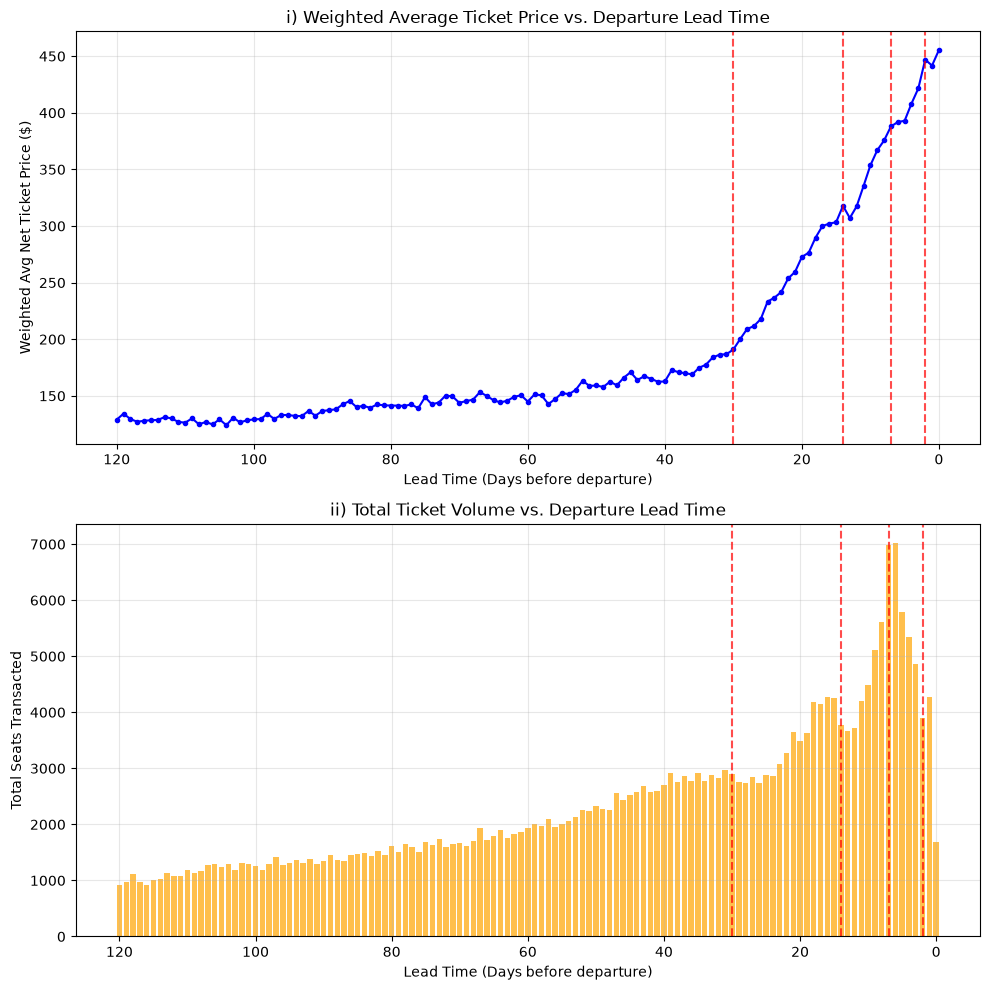

In [158]:

# Load data
df_filtered = df_120 

# Group by lead_days
# Calculate total volume (num_seats_total) and weighted average price
agg_lead = df_filtered.groupby('lead_days').agg(
    total_volume=('num_seats_total', 'sum'),
    total_revenue=('revenue', 'sum') if 'revenue' in df_filtered.columns else ('num_seats_total', 'sum') # fallback
)

# Since revenue might not be in columns, let's explicitly calculate it
if 'revenue' not in df_filtered.columns:
    df_filtered['revenue'] = df_filtered['num_seats_total'] * df_filtered['mean_net_ticket_price']

agg_lead = df_filtered.groupby('lead_days').agg(
    total_volume=('num_seats_total', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

agg_lead['weighted_price'] = agg_lead['total_revenue'] / agg_lead['total_volume']

# Plotting
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Plot 1: Mean Price vs Lead Time
axes[0].plot(agg_lead['lead_days'], agg_lead['weighted_price'], color='blue', marker='o', markersize=3, linestyle='-')
axes[0].set_title('i) Weighted Average Ticket Price vs. Departure Lead Time')
axes[0].set_xlabel('Lead Time (Days before departure)')
axes[0].set_ylabel('Weighted Avg Net Ticket Price ($)')
axes[0].invert_xaxis() # Standard to show time approaching 0
axes[0].grid(True, alpha=0.3)

# Add vertical lines for suggested bins: 2, 7, 14, 30
for v in [2, 7, 14, 30]:
    axes[0].axvline(x=v, color='red', linestyle='--', alpha=0.7)

# Plot 2: Volume vs Lead Time
axes[1].bar(agg_lead['lead_days'], agg_lead['total_volume'], color='orange', alpha=0.7)
axes[1].set_title('ii) Total Ticket Volume vs. Departure Lead Time')
axes[1].set_xlabel('Lead Time (Days before departure)')
axes[1].set_ylabel('Total Seats Transacted')
axes[1].invert_xaxis()
axes[1].grid(True, alpha=0.3)

for v in [2, 7, 14, 30]:
    axes[1].axvline(x=v, color='red', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('lead_time_analysis.png')
plt.show()

## Common lead categories, controls, and reporting helpers
The five intervals are exhaustive and nonoverlapping for eligible integer lead days. Model 1, Test 1, Test 1A, Test 1B, and Test 2 use the applicable lead-category definitions; Test 2 varies only the price-grouping rule. The pooled formulas share train, cabin, return, one-way, customer category, day-of-week, and year-month controls. Reference Model 0 excludes lead-time regression controls, while Model 1 and Test 1 retain the five lead categories. The shared `controls` variable remains unchanged for Model 1 and Test 2; Reference Model 0 defines a separate control string.

The helpers below perform repeated validation, reporting, and plotting. Main-model construction and regression fits remain in separate visible cells. No HC3 warning is suppressed. Both return and one-way indicators are retained as supplied and are not assumed to be logical complements. The numerical rank check does not presume a particular source of collinearity, and the diagnostics report whether price is separately estimable.

**HC3 in plain language:** HC3 is a heteroskedasticity-robust standard-error estimator. It leaves OLS coefficient estimates unchanged while adjusting estimated standard errors, confidence intervals, and p-values, with a stronger adjustment for high-leverage observations than simpler HC estimators. HC3 does not solve price endogeneity or make the conditional associations causal.

In [159]:
LEAD_LABELS = ["0-2 days", "3-7 days", "8-14 days", "15-30 days", ">30 days"]
df_120["lead_category"] = pd.cut(df_120["lead_days"], bins=[-1, 2, 7, 14, 30, np.inf],
                                  labels=LEAD_LABELS, right=True, ordered=True)
assert df_120["lead_category"].notna().all()
display(df_120["lead_category"].value_counts(sort=False))
controls = ("C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway)"
            " + C(Customer_Cat) + C(lead_category) + C(dept_dow) + C(dept_month)")
controls_by_customer = ("C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway)"
                       " + C(lead_category) + C(dept_dow) + C(dept_month)")
print("Shared pooled controls:", controls)

lead_category
0-2 days       5712
3-7 days      13772
8-14 days     16045
15-30 days    27536
>30 days      60926
Name: count, dtype: int64

Shared pooled controls: C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway) + C(Customer_Cat) + C(lead_category) + C(dept_dow) + C(dept_month)


In [160]:
def check_positive_cells(frame, quantity, price):
    bad = (~np.isfinite(frame[quantity]) | ~np.isfinite(frame[price]) |
           frame[quantity].le(0) | frame[price].le(0))
    if bad.any():
        display(frame.loc[bad])
        raise ValueError("Invalid aggregate values; no cells were silently dropped.")

def extract_price(fitted, term):
    ci = fitted.conf_int(alpha=0.05).loc[term]
    return {"Regression N": int(fitted.nobs), "ln(price) coefficient": fitted.params[term],
            "HC3 SE": fitted.bse[term], "t/z-stat": fitted.tvalues[term], "p-value": fitted.pvalues[term],
            "95% CI lower": ci.iloc[0], "95% CI upper": ci.iloc[1],
            "R-squared": fitted.rsquared, "Adjusted R-squared": fitted.rsquared_adj}

def model_diagnostics(fitted, price_term):
    x = fitted.model.exog
    j = fitted.model.exog_names.index(price_term)
    other = np.delete(x, j, axis=1)
    price_residual = x[:, j] - other @ np.linalg.lstsq(other, x[:, j], rcond=None)[0]
    estimable = np.linalg.norm(price_residual) > 1e-8 * max(1.0, np.linalg.norm(x[:, j]))
    hat = fitted.get_influence().hat_matrix_diag
    rank = np.linalg.matrix_rank(x)
    result = {"Design columns": x.shape[1], "Design rank": rank,
              "Residual degrees of freedom": fitted.df_resid, "Price separately estimable": bool(estimable),
              "Maximum leverage": hat.max(), "Cells with leverage >= 0.99": int((hat >= 0.99).sum()),
              "Finite price HC3 SE": bool(np.isfinite(fitted.bse[price_term]))}
    display(pd.Series(result))
    if rank < x.shape[1]:
        warnings.warn("Rank-deficient design: some control coefficients are not uniquely identified.")
    if not estimable:
        warnings.warn("Price is collinear with controls; its reported coefficient is not separately identified.")
    if (hat >= 0.99).any() or fitted.df_resid <= 0 or not result["Finite price HC3 SE"]:
        warnings.warn("High leverage or limited residual information may make HC3 inference unreliable.")
    return result

def aggregation_diagnostics(frame, eligible_source_n):
    n = frame["n_original_records"]
    display(pd.Series({"Eligible source N": eligible_source_n, "Regression cells": len(frame),
        "Aggregation reduction %": 100 * (eligible_source_n - len(frame)) / eligible_source_n,
        "% cells with 1 cleaned record": 100 * n.eq(1).mean(),
        "% cells with 2 cleaned records": 100 * n.eq(2).mean(),
        "% cells with 3+ cleaned records": 100 * n.ge(3).mean(), "Maximum records per cell": n.max()}))
    display(n.describe())
    if "price_range" in frame:
        ranges = {"All cells": frame["price_range"],
                  "Only cells with >=2 records": frame.loc[n >= 2, "price_range"]}
        display(pd.DataFrame({label: values.quantile([0.5, 0.9, 0.95, 0.99, 1.0])
                              for label, values in ranges.items()}))
        if not n.ge(2).any():
            print("No multi-record cells; their conditional price-range statistics are undefined.")

def coefficient_plot(table, label_column, title):
    beta = table["ln(price) coefficient"].to_numpy(dtype=float)
    lower = table["95% CI lower"].to_numpy(dtype=float)
    upper = table["95% CI upper"].to_numpy(dtype=float)
    valid_beta = np.isfinite(beta)
    valid_ci = valid_beta & np.isfinite(lower) & np.isfinite(upper) & (lower <= beta) & (upper >= beta)
    if not valid_ci.all():
        print("Unusable confidence intervals (rows retained in the table):")
        display(table.loc[~valid_ci, [label_column, "ln(price) coefficient", "HC3 SE", "95% CI lower", "95% CI upper"]])
    x = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(x[valid_ci], beta[valid_ci],
                yerr=np.vstack([beta[valid_ci] - lower[valid_ci], upper[valid_ci] - beta[valid_ci]]), fmt="o")
    if (valid_beta & ~valid_ci).any():
        ax.plot(x[valid_beta & ~valid_ci], beta[valid_beta & ~valid_ci], "o")
    ax.axhline(0)
    ax.set_xticks(x)
    ax.set_xticklabels(table[label_column].astype(str), rotation=25, ha="right")
    ax.set_ylabel("Estimated ln(price) coefficient")
    ax.set_xlabel("Specification")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

def pvalue_for_display(value):
    """Format only the displayed copy; keep the underlying numeric p-value unchanged."""
    try:
        numeric = float(value)
    except (TypeError, ValueError):
        return value
    return "< 0.001" if np.isfinite(numeric) and numeric < 0.001 else value

def format_pvalues_for_display(table):
    shown = table.copy()
    for column in shown.columns:
        if "p-value" in str(column).lower():
            shown[column] = shown[column].map(pvalue_for_display)
    return shown

def format_pvalue_metric_rows_for_display(table, metric_column="Metric"):
    shown = table.copy()
    pvalue_rows = shown[metric_column].astype(str).str.lower().str.contains("p-value", regex=False)
    for column in shown.columns:
        if column != metric_column:
            shown[column] = shown[column].astype(object)
            shown.loc[pvalue_rows, column] = shown.loc[pvalue_rows, column].map(pvalue_for_display)
    return shown

def format_statsmodels_summary_pvalues(fitted):
    """Retain the statsmodels summary while replacing displayed p-values below 0.001."""
    import re

    lines = fitted.summary().as_text().splitlines()
    parameter_pvalues = np.asarray(fitted.pvalues, dtype=float)
    in_parameter_table = False
    parameter_row = 0
    number_pattern = re.compile(r"[-+]?(?:\d+\.\d+|\d+)(?:e[-+]?\d+)?", re.IGNORECASE)

    for i, line in enumerate(lines):
        if "P>|z|" in line or "P>|t|" in line:
            in_parameter_table = True
            continue

        if in_parameter_table and parameter_row < len(parameter_pvalues):
            matches = list(number_pattern.finditer(line))
            if len(matches) >= 6:
                if parameter_pvalues[parameter_row] < 0.001:
                    pvalue_match = matches[-3]
                    line = line[:pvalue_match.start()] + "< 0.001" + line[pvalue_match.end():]
                    lines[i] = line
                parameter_row += 1

        if "Prob (F-statistic):" in line and np.isfinite(fitted.f_pvalue) and fitted.f_pvalue < 0.001:
            lines[i] = re.sub(
                r"(Prob \(F-statistic\):\s+)\S+",
                lambda match: match.group(1) + "< 0.001",
                lines[i],
                count=1,
            )

    return "\n".join(lines)


## Reference Model 0: Reference Specification Without Lead-Time Controls
Use the supplied 120-day sample, exact observed price, existing semi-aggregated record quantity, log-log OLS, the existing non-lead controls, and HC3 standard errors. No lead-time regressor is included.

Strict grouping was attempted using identical observed price and the relevant record characteristics, including exact purchase date. In the supplied data, **all resulting combinations are unique: 123,991 source observations remain 123,991 regression observations, with 0% additional aggregation**. Thus this reference effectively retains the original semi-aggregated observations; it does not create a new aggregated demand measure. Keep the grouping and multiplicity checks to verify this when data change.

The existing grouping keys remain purchase date, departure date, train, cabin, return, one-way, customer category, and exact price. Stored lead variables are available for audit but are not included in this regression. The comparison with Model 1 assesses how adding booking-stage controls relates to the price coefficient, conditional on the observation-equivalence check. Neither coefficient is interpreted causally.

In [161]:
strict_keys = ["purchase_date", "dept_date", "Train_Number_All", "isNormCabin", "isReturn",
               "isOneway", "Customer_Cat", "mean_net_ticket_price"]
reference_model0_data = (df_120.groupby(strict_keys, observed=True, dropna=False, sort=False)
    .agg(Q_0=("num_seats_total", "sum"), n_original_records=("_source_row", "size"),
         lead_days=("lead_days", "first"), lead_category=("lead_category", "first"),
         dept_dow=("dept_dow", "first"), dept_month=("dept_month", "first"))
    .reset_index().rename(columns={"mean_net_ticket_price": "P_0"}))
for col in reference_model0_data.select_dtypes(include="category").columns:
    reference_model0_data[col] = reference_model0_data[col].cat.remove_unused_categories()
assert reference_model0_data["n_original_records"].sum() == source_N
assert np.isclose(reference_model0_data["Q_0"].sum(), df_120["num_seats_total"].sum())
check_positive_cells(reference_model0_data, "Q_0", "P_0")
reference_model0_data["ln_Q_0"] = np.log(reference_model0_data["Q_0"])
reference_model0_data["ln_P_0"] = np.log(reference_model0_data["P_0"])
controls_reference_model0 = ("C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway)"
                   " + C(Customer_Cat) + C(dept_dow) + C(dept_month)")
formula_reference0 = "ln_Q_0 ~ ln_P_0 + " + controls_reference_model0
assert set(controls.split(" + ")) - set(controls_reference_model0.split(" + ")) == {"C(lead_category)"}
assert not (set(controls_reference_model0.split(" + ")) - set(controls.split(" + ")))
print(formula_reference0)
aggregation_diagnostics(reference_model0_data, source_N)
if reference_model0_data["n_original_records"].eq(1).all():
    print("Every strict cell has one cleaned record: strict aggregation equals no additional aggregation for this sample.")
else:
    print("Some strict cells combine records; this sample is not equivalent to no aggregation.")
    display(reference_model0_data.loc[reference_model0_data["n_original_records"] >= 2].nlargest(10, "n_original_records"))
display(reference_model0_data[["purchase_date", "dept_date", "Train_Number_All", "Customer_Cat",
                     "Q_0", "P_0", "n_original_records", "lead_days", "lead_category", "dept_month"]].head())

ln_Q_0 ~ ln_P_0 + C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway) + C(Customer_Cat) + C(dept_dow) + C(dept_month)


Eligible source N                  123991.0
Regression cells                   123991.0
Aggregation reduction %                 0.0
% cells with 1 cleaned record         100.0
% cells with 2 cleaned records          0.0
% cells with 3+ cleaned records         0.0
Maximum records per cell                1.0
dtype: float64

count    123991.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0
Name: n_original_records, dtype: float64

Every strict cell has one cleaned record: strict aggregation equals no additional aggregation for this sample.


,purchase_date,dept_date,Train_Number_All,Customer_Cat,Q_0,P_0,n_original_records,lead_days,lead_category,dept_month
0,2018-10-17,2019-02-14,A,A,1,237.930212,1,120,>30 days,2019-02
1,2018-10-26,2019-02-23,E,A,1,116.869129,1,120,>30 days,2019-02
2,2018-10-26,2019-02-23,J,A,1,116.534979,1,120,>30 days,2019-02
3,2018-10-26,2019-02-23,A,A,2,116.696692,1,120,>30 days,2019-02
4,2018-11-23,2019-03-23,K,A,1,277.608319,1,120,>30 days,2019-03


In [162]:
reference_model0 = smf.ols(formula_reference0, data=reference_model0_data, missing="raise").fit(cov_type="HC3")
assert int(reference_model0.nobs) == len(reference_model0_data)

In [163]:
print(format_statsmodels_summary_pvalues(reference_model0))

                            OLS Regression Results                            
Dep. Variable:                 ln_Q_0   R-squared:                       0.128
Model:                            OLS   Adj. R-squared:                  0.128
Method:                 Least Squares   F-statistic:                     636.6
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               < 0.001
Time:                        18:16:42   Log-Likelihood:            -1.1391e+05
No. Observations:              123991   AIC:                         2.279e+05
Df Residuals:                  123956   BIC:                         2.282e+05
Df Model:                          34                                         
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept            

In [164]:
reference_model0_diagnostics = model_diagnostics(reference_model0, "ln_P_0")
reference_model0_result = {"Model": "Reference Model 0: reference without lead-time controls", "Source N": source_N,
                 "Aggregation reduction %": 100 * (source_N - len(reference_model0_data)) / source_N, **extract_price(reference_model0, "ln_P_0")}
display(format_pvalues_for_display(pd.DataFrame([reference_model0_result])))

Design columns                       35
Design rank                          35
Residual degrees of freedom    123956.0
Price separately estimable         True
Maximum leverage                    1.0
Cells with leverage >= 0.99           1
Finite price HC3 SE                True
dtype: object

C:\Users\aatmi\AppData\Local\Temp\ipykernel_32656\3065665930.py:33: UserWarning: High leverage or limited residual information may make HC3 inference unreliable.
  warnings.warn("High leverage or limited residual information may make HC3 inference unreliable.")


,Model,Source N,Aggregation reduction %,Regression N,ln(price) coefficient,HC3 SE,t/z-stat,p-value,95% CI lower,95% CI upper,R-squared,Adjusted R-squared
0,Reference Model 0: reference without lead-time...,123991,0.0,123991,-0.206706,0.004721,-43.784165,< 0.001,-0.215959,-0.197453,0.128123,0.127884


## Model 1: Main Specification With Exact Observed Prices and Lead-Time Controls
This is the **main specification**, using the **120-day analysis sample**, **exact observed prices**, the **five agreed lead-time categorical controls**, the **original semi-aggregated record-level quantity**, the existing other controls, and HC3 OLS inference.

Strict grouping was attempted using identical observed price and the relevant record characteristics. However, no additional aggregation occurred because all resulting combinations were unique: **123,991 source observations remain 123,991 regression observations**. Model 1 therefore effectively retains the original semi-aggregated observations and their exact observed price variation.

The existing verification code retains departure date, train, cabin, return/one-way indicators, customer category, lead category, and exact observed price as keys. Price is not rounded or averaged in Model 1. Runtime diagnostics continue to report whether records combine, and a 0% empirical reduction is not described as a new aggregated demand measure.

In [165]:
product_timing_keys = ["dept_date", "Train_Number_All", "isNormCabin", "isReturn", "isOneway",
                 "Customer_Cat", "lead_category"]
baseline_keys = product_timing_keys + ["mean_net_ticket_price"]
baseline_source = df_120.copy()
baseline_source["_price_times_seats"] = baseline_source["mean_net_ticket_price"] * baseline_source["num_seats_total"]
model1_data = (baseline_source.groupby(baseline_keys, observed=True, dropna=False, sort=False)
    .agg(Q_1=("num_seats_total", "sum"), revenue_like=("_price_times_seats", "sum"),
         n_original_records=("_source_row", "size"), dept_dow=("dept_dow", "first"),
         dept_month=("dept_month", "first"), min_actual_price=("mean_net_ticket_price", "min"),
         max_actual_price=("mean_net_ticket_price", "max"), min_lead_days=("lead_days", "min"),
         max_lead_days=("lead_days", "max")).reset_index())
model1_data["P_1"] = model1_data["mean_net_ticket_price"]
assert model1_data["min_actual_price"].eq(model1_data["max_actual_price"]).all()
assert model1_data["P_1"].eq(model1_data["mean_net_ticket_price"]).all()
model1_data["price_range"] = model1_data["max_actual_price"] - model1_data["min_actual_price"]
for col in model1_data.select_dtypes(include="category").columns:
    model1_data[col] = model1_data[col].cat.remove_unused_categories()
assert model1_data["n_original_records"].sum() == source_N
assert np.isclose(model1_data["Q_1"].sum(), df_120["num_seats_total"].sum())
assert np.isclose(model1_data["revenue_like"].sum(), baseline_source["_price_times_seats"].sum())
assert (model1_data["P_1"] >= model1_data["min_actual_price"] - 1e-8).all()
assert (model1_data["P_1"] <= model1_data["max_actual_price"] + 1e-8).all()
assert len(model1_data) <= source_N
check_positive_cells(model1_data, "Q_1", "P_1")
model1_data["ln_Q_1"] = np.log(model1_data["Q_1"])
model1_data["ln_P_1"] = np.log(model1_data["P_1"])
display(model1_data.head())

print("Main Model 1 source observations:", source_N, "; regression observations:", len(model1_data))
if model1_data["n_original_records"].eq(1).all():
    print("No additional aggregation occurred: Model 1 retains the original semi-aggregated record quantities and exact observed price variation.")
else:
    print("The loaded file differs from the documented zero-aggregation case; inspect the combined records before describing the observation unit.")

,dept_date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,lead_category,mean_net_ticket_price,Q_1,revenue_like,n_original_records,dept_dow,dept_month,min_actual_price,max_actual_price,min_lead_days,max_lead_days,P_1,price_range,ln_Q_1,ln_P_1
0,2019-02-14,A,0,1,0,A,>30 days,237.930212,1,237.930212,1,3,2019-02,237.930212,237.930212,120,120,237.930212,0.0,0.000000,5.471977
1,2019-02-23,E,1,0,0,A,>30 days,116.869129,1,116.869129,1,5,2019-02,116.869129,116.869129,120,120,116.869129,0.0,0.000000,4.761055
2,2019-02-23,J,1,0,0,A,>30 days,116.534979,1,116.534979,1,5,2019-02,116.534979,116.534979,120,120,116.534979,0.0,0.000000,4.758191
3,2019-02-23,A,1,0,0,A,>30 days,116.696692,2,233.393384,1,5,2019-02,116.696692,116.696692,120,120,116.696692,0.0,0.693147,4.759578
4,2019-03-23,K,0,1,0,A,>30 days,277.608319,1,277.608319,1,5,2019-03,277.608319,277.608319,120,120,277.608319,0.0,0.000000,5.626211


Main Model 1 source observations: 123991 ; regression observations: 123991
No additional aggregation occurred: Model 1 retains the original semi-aggregated record quantities and exact observed price variation.


### Verify the observation unit and lack of additional aggregation
Read the source N, regression N, percentage reduction, and multiplicities together. With 0% reduction, the exact-price specification remains at the original semi-aggregated record level. Within-group price ranges must be zero by construction; they are not evidence about unrestricted price dispersion. The main diagnostics remain in place so future changes in the input file are visible.

In [166]:
aggregation_diagnostics(model1_data, source_N)
baseline_example_columns = baseline_keys + ["Q_1", "P_1", "n_original_records", "min_actual_price",
                                           "max_actual_price", "price_range", "min_lead_days", "max_lead_days"]
print("Largest combined cells:")
display(model1_data.loc[model1_data["n_original_records"] >= 2]
        .nlargest(10, "n_original_records")[baseline_example_columns])
print("Exact-price check: displayed ranges must be zero:")
display(model1_data.nlargest(10, "price_range")[baseline_example_columns])

Eligible source N                  123991.0
Regression cells                   123991.0
Aggregation reduction %                 0.0
% cells with 1 cleaned record         100.0
% cells with 2 cleaned records          0.0
% cells with 3+ cleaned records         0.0
Maximum records per cell                1.0
dtype: float64

count    123991.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0
Name: n_original_records, dtype: float64

,All cells,Only cells with >=2 records
0.50,0.0,NaN
0.90,0.0,NaN
0.95,0.0,NaN
0.99,0.0,NaN
1.00,0.0,NaN


No multi-record cells; their conditional price-range statistics are undefined.
Largest combined cells:


,dept_date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,lead_category,mean_net_ticket_price,Q_1,P_1,n_original_records,min_actual_price,max_actual_price,price_range,min_lead_days,max_lead_days


Exact-price check: displayed ranges must be zero:


,dept_date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,lead_category,mean_net_ticket_price,Q_1,P_1,n_original_records,min_actual_price,max_actual_price,price_range,min_lead_days,max_lead_days
0,2019-02-14,A,0,1,0,A,>30 days,237.930212,1,237.930212,1,237.930212,237.930212,0.0,120,120
1,2019-02-23,E,1,0,0,A,>30 days,116.869129,1,116.869129,1,116.869129,116.869129,0.0,120,120
2,2019-02-23,J,1,0,0,A,>30 days,116.534979,1,116.534979,1,116.534979,116.534979,0.0,120,120
3,2019-02-23,A,1,0,0,A,>30 days,116.696692,2,116.696692,1,116.696692,116.696692,0.0,120,120
4,2019-03-23,K,0,1,0,A,>30 days,277.608319,1,277.608319,1,277.608319,277.608319,0.0,120,120
5,2018-10-18,H,0,0,0,A,>30 days,251.791415,1,251.791415,1,251.791415,251.791415,0.0,120,120
6,2019-06-29,D,1,1,0,A,>30 days,108.831129,1,108.831129,1,108.831129,108.831129,0.0,120,120
7,2018-10-10,J,0,1,0,A,>30 days,457.961958,1,457.961958,1,457.961958,457.961958,0.0,119,119
8,2019-02-22,F,1,0,0,A,>30 days,118.767519,1,118.767519,1,118.767519,118.767519,0.0,119,119
9,2019-02-22,G,0,1,0,A,>30 days,360.273745,1,360.273745,1,360.273745,360.273745,0.0,119,119


### Estimate the fixed main specification with HC3
In the supplied zero-aggregation case, quantity is the original semi-aggregated record's seats and price is its exact observed fare. The five lead categories control booking stage. Keep the existing formula and sample regardless of the coefficient sign; exact-price grouping does not solve endogeneity.

In [167]:
formula1 = "ln_Q_1 ~ ln_P_1 + " + controls
print(formula1)

ln_Q_1 ~ ln_P_1 + C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway) + C(Customer_Cat) + C(lead_category) + C(dept_dow) + C(dept_month)


In [168]:
model1 = smf.ols(formula1, data=model1_data, missing="raise").fit(cov_type="HC3")
assert int(model1.nobs) == len(model1_data)

In [169]:
print(format_statsmodels_summary_pvalues(model1))

                            OLS Regression Results                            
Dep. Variable:                 ln_Q_1   R-squared:                       0.136
Model:                            OLS   Adj. R-squared:                  0.136
Method:                 Least Squares   F-statistic:                     619.4
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               < 0.001
Time:                        18:16:45   Log-Likelihood:            -1.1333e+05
No. Observations:              123991   AIC:                         2.267e+05
Df Residuals:                  123952   BIC:                         2.271e+05
Df Model:                          38                                         
Covariance Type:                  HC3                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept

In [170]:
model1_diagnostics = model_diagnostics(model1, "ln_P_1")
model1_result = {"Model": "Model 1: Main specification, exact observed price", "Source N": source_N,
                 "Aggregation reduction %": 100 * (source_N - len(model1_data)) / source_N,
                 **extract_price(model1, "ln_P_1")}

Design columns                       39
Design rank                          39
Residual degrees of freedom    123952.0
Price separately estimable         True
Maximum leverage                    1.0
Cells with leverage >= 0.99           1
Finite price HC3 SE                True
dtype: object

C:\Users\aatmi\AppData\Local\Temp\ipykernel_32656\3065665930.py:33: UserWarning: High leverage or limited residual information may make HC3 inference unreliable.
  warnings.warn("High leverage or limited residual information may make HC3 inference unreliable.")


### Reference Model 0 vs Model 1: adding booking-stage controls
Reference Model 0 is the reference **without lead-time controls**; Model 1 retains the five lead categories. Both use the same selected source records and other pooled regression controls. Read the compact HC3 results and the signed difference `beta_Model1 - beta_ReferenceModel0` below. The difference is descriptive, not a causal effect or a formal test of the difference between correlated estimates.

The original exact-purchase-date and lead-category aggregation rules are preserved. Check that they produce one-to-one equivalent regression cells, quantities, prices, and shared control values. If they do, the specification comparison isolates adding lead controls within this sample. If not, any coefficient difference also reflects the changed aggregation unit.

,Model,ln(price) coefficient,HC3 SE,95% CI lower,95% CI upper,p-value,N,R-squared,Adjusted R-squared
0,Reference Model 0: reference without lead-time...,-0.206706,0.004721,-0.215959,-0.197453,< 0.001,123991,0.128123,0.127884
1,"Model 1: Main specification, exact observed price",-0.252765,0.005243,-0.263042,-0.242489,< 0.001,123991,0.136150,0.135885


Model 1 coefficient minus Reference Model 0 coefficient            -0.046059
Absolute coefficient change relative to |Reference Model 0| (%)    22.282454
dtype: float64

Equivalent regression cells, prices, quantities, and shared controls: True


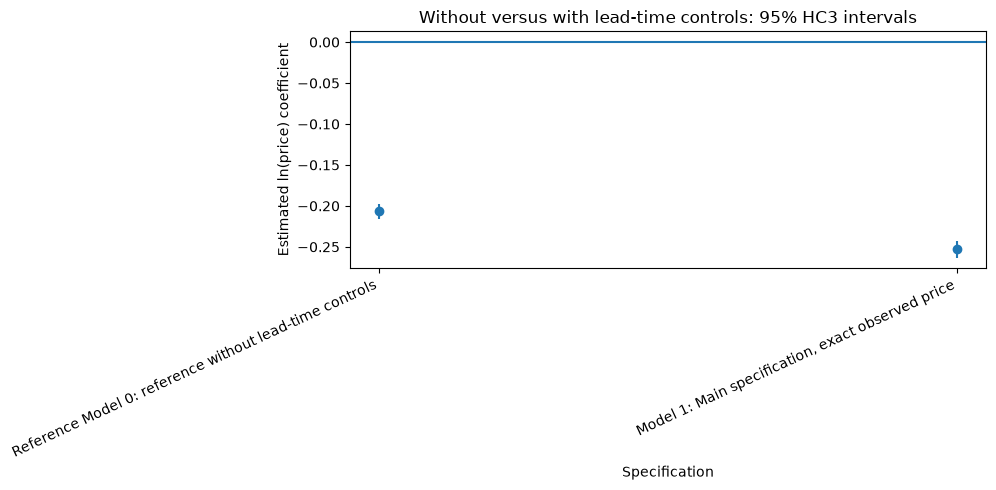

In [171]:
main_comparison = pd.DataFrame([reference_model0_result, model1_result])
compact_main_comparison = main_comparison[["Model", "ln(price) coefficient", "HC3 SE",
    "95% CI lower", "95% CI upper", "p-value", "Regression N", "R-squared", "Adjusted R-squared"]].rename(
    columns={"Regression N": "N"})
display(format_pvalues_for_display(compact_main_comparison))

beta_reference_model0 = reference_model0.params["ln_P_0"]
beta_model1 = model1.params["ln_P_1"]
model1_minus_reference_model0 = beta_model1 - beta_reference_model0
relative_coefficient_change = (abs(model1_minus_reference_model0) / abs(beta_reference_model0) if beta_reference_model0 != 0 else np.nan)
display(pd.Series({"Model 1 coefficient minus Reference Model 0 coefficient": model1_minus_reference_model0,
                   "Absolute coefficient change relative to |Reference Model 0| (%)": 100 * relative_coefficient_change}))

comparison_ref0_cells = reference_model0_data.rename(columns={"P_0": "mean_net_ticket_price"})
comparison_alignment = comparison_ref0_cells.merge(
    model1_data[baseline_keys + ["Q_1", "dept_dow", "dept_month"]],
    on=baseline_keys, how="outer", validate="many_to_one", indicator=True, suffixes=("_ref0", "_main1"))
same_regression_cells = bool(
    len(reference_model0_data) == len(model1_data) == len(comparison_alignment)
    and not comparison_ref0_cells.duplicated(baseline_keys).any()
    and comparison_alignment["_merge"].eq("both").all()
    and np.allclose(comparison_alignment["Q_0"], comparison_alignment["Q_1"])
    and comparison_alignment["dept_dow_ref0"].eq(comparison_alignment["dept_dow_main1"]).all()
    and comparison_alignment["dept_month_ref0"].eq(comparison_alignment["dept_month_main1"]).all())
print("Equivalent regression cells, prices, quantities, and shared controls:", same_regression_cells)
del comparison_ref0_cells, comparison_alignment
coefficient_plot(main_comparison, "Model", "Without versus with lead-time controls: 95% HC3 intervals")

### Interpretation after running
The next cell generates an interpretation from the fitted results. For explicit descriptive reporting, the editable `MATERIAL_RELATIVE_CHANGE = 0.20` labels an absolute coefficient shift of at least 20% of the reference magnitude as material; a sign reversal is also flagged. This is a reporting convention, not a statistical significance test or a universal economic threshold. The table and exact changes remain available for your own assessment. Compare HC3 intervals and the existing leverage diagnostics before discussing inference.

In [172]:
MATERIAL_RELATIVE_CHANGE = 0.20  # Descriptive convention only; adjust with an economic justification.
if not np.isfinite([beta_reference_model0, beta_model1]).all():
    display(Markdown("At least one coefficient is nonfinite; review the regression diagnostics before interpreting this comparison."))
else:
    sign_changed = np.sign(beta_reference_model0) != np.sign(beta_model1)
    if not np.isfinite(relative_coefficient_change):
        change_description = "Relative change is undefined because the reference coefficient is zero; assess the absolute difference."
    elif sign_changed:
        change_description = "The sign changes, indicating a substantial change in the estimated conditional relationship."
    elif relative_coefficient_change >= MATERIAL_RELATIVE_CHANGE:
        change_description = "The coefficient change is material under the stated descriptive reporting rule."
    else:
        change_description = "The coefficient change is below the stated descriptive materiality threshold."
    comparison_scope = (
        "The aggregation rules yield equivalent observations here, so the regression specification change is the addition of the five lead-time controls."
        if same_regression_cells else
        "The aggregation rules yield different observations here; the change cannot be attributed solely to adding lead-time controls.")
    display(Markdown(f"**Reference without lead controls:** {beta_reference_model0:.4f}; "
        f"**Model 1 with lead controls:** {beta_model1:.4f}. "
        f"Model 1 minus Reference Model 0 = {model1_minus_reference_model0:+.4f}; "
        f"absolute shift relative to the reference magnitude = {relative_coefficient_change:.1%}. "
        + change_description + " " + comparison_scope +
        " These are conditional price–quantity associations; neither coefficient nor their difference is interpreted causally."))

**Reference without lead controls:** -0.2067; **Model 1 with lead controls:** -0.2528. Model 1 minus Reference Model 0 = -0.0461; absolute shift relative to the reference magnitude = 22.3%. The coefficient change is material under the stated descriptive reporting rule. The aggregation rules yield equivalent observations here, so the regression specification change is the addition of the five lead-time controls. These are conditional price–quantity associations; neither coefficient nor their difference is interpreted causally.

## Add-on Checks: Heteroskedasticity Diagnostics
These diagnostics reuse the fitted MAIN Model 1 and its complete 120-day regression sample. They assess residual dispersion and the suitability of heteroskedasticity-robust inference without changing the official Model 1 specification.

### Residuals vs Fitted Values
The Residuals vs Fitted plot visually assesses the homoskedasticity assumption. If the vertical spread of signed residuals changes systematically across fitted values, this may indicate non-constant variance.

All Model 1 observations are plotted using very small, transparent points; no regression or plotting subsample is used.

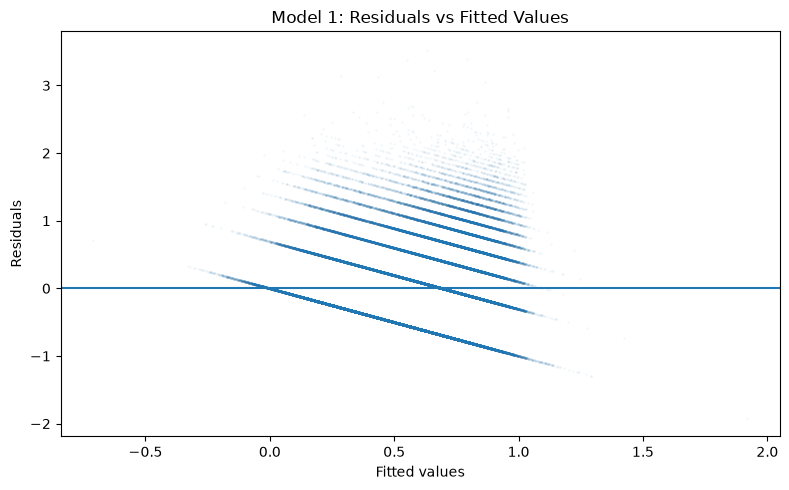

In [173]:
model1_fitted_values = np.asarray(model1.fittedvalues)
model1_residuals = np.asarray(model1.resid)
model1_absolute_residuals = np.abs(model1_residuals)
model1_design_matrix = np.asarray(model1.model.exog)
assert len(model1_fitted_values) == len(model1_residuals) == model1_design_matrix.shape[0]
assert len(model1_residuals) == int(model1.nobs) == len(model1_data)

model1_residual_plot_data = pd.DataFrame({
    "fitted_value": model1_fitted_values,
    "residual": model1_residuals,
    "absolute_residual": model1_absolute_residuals,
})
model1_residual_plot_data["fitted_bin"] = pd.qcut(
    model1_residual_plot_data["fitted_value"], q=20, duplicates="drop")
model1_binned_residual_spread = (
    model1_residual_plot_data.groupby("fitted_bin", observed=True)
    .agg(mean_fitted_value=("fitted_value", "mean"),
         mean_absolute_residual=("absolute_residual", "mean"),
         observations=("residual", "size"))
    .reset_index(drop=True)
)
spread_values = model1_binned_residual_spread["mean_absolute_residual"].to_numpy()
spread_min = float(spread_values.min())
spread_max = float(spread_values.max())
spread_relative_range = ((spread_max - spread_min) / spread_min if spread_min > 0 else np.inf)
residual_spread_changes = bool(spread_relative_range > 0.10)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(model1_fitted_values, model1_residuals, s=1, alpha=0.03)
ax.axhline(0)
ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("Model 1: Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

Diagonal bands arise partly because the dependent variable is a discrete seat count after log transformation. The relevant feature for assessing heteroskedasticity is the changing vertical spread of residuals rather than the existence of the bands themselves.

### Absolute Residuals vs Fitted Values
This complementary plot displays prediction-error magnitude directly. Fitted values are divided into approximately 20 equal-frequency bins; the line connects each bin's mean fitted value and mean absolute residual.

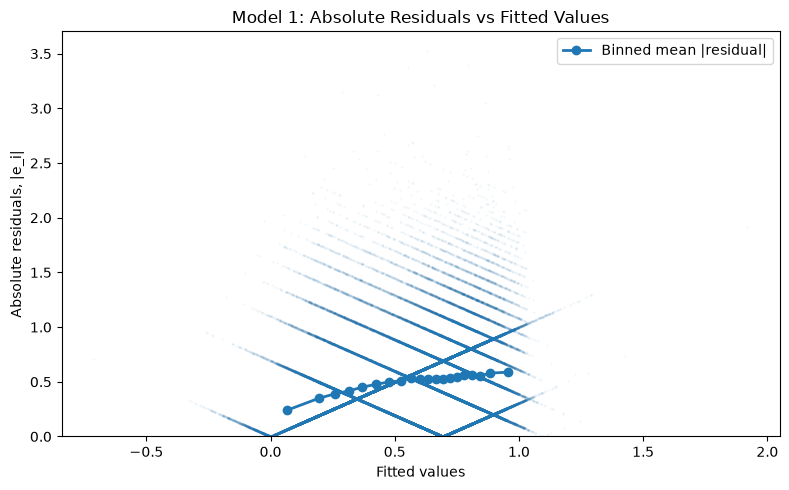

In [174]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(model1_fitted_values, model1_absolute_residuals, s=1, alpha=0.03)
ax.plot(model1_binned_residual_spread["mean_fitted_value"],
        model1_binned_residual_spread["mean_absolute_residual"],
        marker="o", linewidth=2, label="Binned mean |residual|")
ax.set_xlabel("Fitted values")
ax.set_ylabel("Absolute residuals, |e_i|")
ax.set_title("Model 1: Absolute Residuals vs Fitted Values")
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

The binned mean absolute residual trend summarizes how prediction-error magnitude changes across fitted values. A non-flat pattern provides visual evidence that residual dispersion is not constant.

This visual pattern does not by itself prove heteroskedasticity.

### Breusch-Pagan Test
The hypotheses are:

- **H0:** Residual variance is constant (homoskedasticity).
- **H1:** Residual variance is non-constant and related to the regressors (heteroskedasticity).

The test uses MAIN Model 1 residuals and its regression design matrix for the complete Model 1 sample.

In [175]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_lm_stat, bp_lm_pvalue, bp_f_stat, bp_f_pvalue = het_breuschpagan(
    model1_residuals, model1_design_matrix)

def format_diagnostic_pvalue(value):
    return "< 0.001" if value < 0.001 else f"{value:.3f}"

bp_results = pd.DataFrame([{
    "LM statistic": bp_lm_stat,
    "LM-test p-value": format_diagnostic_pvalue(bp_lm_pvalue),
    "F statistic": bp_f_stat,
    "F-test p-value": format_diagnostic_pvalue(bp_f_pvalue),
}])
display(bp_results)
print("Breusch-Pagan design matrix shape:", model1_design_matrix.shape)
print("Breusch-Pagan residual count:", len(model1_residuals))

bp_lm_rejects = bool(bp_lm_pvalue < 0.05)
bp_f_rejects = bool(bp_f_pvalue < 0.05)
if bp_lm_rejects and bp_f_rejects:
    bp_interpretation = "Both p-values are below 0.05, providing statistical evidence against homoskedasticity."
elif bp_lm_rejects or bp_f_rejects:
    bp_interpretation = "One reported p-value is below 0.05, providing some statistical evidence against homoskedasticity."
else:
    bp_interpretation = "Both p-values are at least 0.05, so there is insufficient evidence to reject homoskedasticity; this does not prove constant variance."
display(Markdown("**Breusch-Pagan interpretation:** " + bp_interpretation))

,LM statistic,LM-test p-value,F statistic,F-test p-value
0,5370.607164,< 0.001,147.684178,< 0.001


Breusch-Pagan design matrix shape: (123991, 39)
Breusch-Pagan residual count: 123991


**Breusch-Pagan interpretation:** Both p-values are below 0.05, providing statistical evidence against homoskedasticity.

### Conventional vs HC3 Inference for the Model 1 Price Coefficient
This comparison uses the identical OLS formula and sample. It illustrates changes in estimated uncertainty only; it is not used to select the model based on significance.

In [176]:
model1_conventional = smf.ols(formula1, data=model1_data, missing="raise").fit()
assert int(model1_conventional.nobs) == len(model1_data)
assert np.isclose(model1_conventional.params["ln_P_1"], model1.params["ln_P_1"], atol=1e-12)

def inference_row(label, fitted):
    ci = fitted.conf_int(alpha=0.05).loc["ln_P_1"]
    return {
        "Standard error method": label,
        "ln(price) coefficient": fitted.params["ln_P_1"],
        "Standard error": fitted.bse["ln_P_1"],
        "95% CI lower": ci.iloc[0],
        "95% CI upper": ci.iloc[1],
        "p-value": fitted.pvalues["ln_P_1"],
    }

ols_vs_hc3 = pd.DataFrame([
    inference_row("Conventional OLS SE", model1_conventional),
    inference_row("HC3 robust SE", model1),
])
display(format_pvalues_for_display(ols_vs_hc3))
print("The ln(price) coefficient is identical across the two rows:",
      np.isclose(ols_vs_hc3["ln(price) coefficient"].iloc[0],
                 ols_vs_hc3["ln(price) coefficient"].iloc[1], atol=1e-12))

,Standard error method,ln(price) coefficient,Standard error,95% CI lower,95% CI upper,p-value
0,Conventional OLS SE,-0.252765,0.005135,-0.262830,-0.242701,< 0.001
1,HC3 robust SE,-0.252765,0.005243,-0.263042,-0.242489,< 0.001


The ln(price) coefficient is identical across the two rows: True


In [177]:
if residual_spread_changes and (bp_lm_rejects or bp_f_rejects):
    hc3_evidence_note = (
        "The residual plots suggest non-constant dispersion, while the Breusch-Pagan test provides formal statistical evidence against homoskedasticity. We therefore report HC3 heteroskedasticity-robust standard errors."
    )
elif bp_lm_rejects or bp_f_rejects:
    hc3_evidence_note = (
        "The visual evidence is not strong, but the Breusch-Pagan test provides statistical evidence against homoskedasticity. We therefore report HC3 heteroskedasticity-robust standard errors."
    )
else:
    hc3_evidence_note = (
        "The diagnostics do not provide strong statistical evidence of heteroskedasticity, so HC3 is retained as a conservative robustness choice."
    )
display(Markdown(
    hc3_evidence_note + " Model 1 remains an OLS regression. HC3 leaves OLS coefficient estimates unchanged but adjusts estimated standard errors, confidence intervals, and p-values. It also gives stronger adjustment to high-leverage observations than simpler HC estimators. HC3 does not solve price endogeneity; the coefficients remain conditional associations rather than causal effects."
))

The residual plots suggest non-constant dispersion, while the Breusch-Pagan test provides formal statistical evidence against homoskedasticity. We therefore report HC3 heteroskedasticity-robust standard errors. Model 1 remains an OLS regression. HC3 leaves OLS coefficient estimates unchanged but adjusts estimated standard errors, confidence intervals, and p-values. It also gives stronger adjustment to high-leverage observations than simpler HC estimators. HC3 does not solve price endogeneity; the coefficients remain conditional associations rather than causal effects.

### Add-on Check: Model 1 Excluding the Rare-Train Observation
First identify every MAIN Model 1 observation with leverage at least 0.99 and map it back to the eligible cleaned source records. The output displays the supplied rare-train flag before attributing the leverage pattern to a rare train. In the current zero-additional-aggregation case, each fitted Model 1 observation maps to one source record.

In [178]:
model1_row_labels = list(model1.model.data.row_labels)
assert model1_data.index.is_unique and len(model1_row_labels) == int(model1.nobs)
model1_leverage_cells = model1_data.loc[model1_row_labels].copy()
model1_leverage_cells["leverage"] = model1.get_influence().hat_matrix_diag
if "flag_rare_train" not in df_120:
    raise ValueError("flag_rare_train is missing; no train label will be assumed.")

model1_source_with_leverage = df_120.merge(
    model1_leverage_cells[baseline_keys + ["leverage", "n_original_records"]],
    on=baseline_keys, how="left", validate="many_to_one")
assert len(model1_source_with_leverage) == len(df_120)
assert model1_source_with_leverage["leverage"].notna().all()

model1_high_leverage_cells = model1_leverage_cells.loc[model1_leverage_cells["leverage"] >= 0.99]
model1_high_leverage_sources = model1_source_with_leverage.loc[
    model1_source_with_leverage["leverage"] >= 0.99]
print("MAIN Model 1 observations with leverage >= 0.99:", len(model1_high_leverage_cells))
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(model1_high_leverage_sources[[
        "Train_Number_All", "dept_date", "purchase_date", "mean_net_ticket_price",
        "num_seats_total", "lead_days", "lead_category", "Customer_Cat",
        "flag_rare_train", "leverage"
    ]])

high_rare_true, high_rare_missing = read_boolean_flag(
    model1_high_leverage_sources["flag_rare_train"], "flag_rare_train")
if len(model1_high_leverage_sources) == 0:
    high_leverage_flag_note = "No Model 1 observations meet the leverage >= 0.99 threshold."
elif high_rare_true.all():
    high_leverage_flag_note = "The displayed output confirms that every leverage >= 0.99 source record is flagged as a rare train."
else:
    high_leverage_flag_note = (
        f"Only {int(high_rare_true.sum())} of {len(model1_high_leverage_sources)} displayed high-leverage source records is flagged as a rare train; attribution should therefore remain cautious."
    )
display(Markdown(high_leverage_flag_note))

MAIN Model 1 observations with leverage >= 0.99: 1


,Train_Number_All,dept_date,purchase_date,mean_net_ticket_price,num_seats_total,lead_days,lead_category,Customer_Cat,flag_rare_train,leverage
112020,O,2018-12-28,2018-12-20,651.752209,1,8,8-14 days,B,True,1.0


The displayed output confirms that every leverage >= 0.99 source record is flagged as a rare train.

Exclude only source records for which `flag_rare_train == True`, then rebuild the same Model 1 exact observed price construction and refit the identical log-log OLS formula with the same controls, lead categories, and HC3 standard errors. The official Model 1 remains unchanged; this is a separate sensitivity check.

In [179]:
model1_rare_flag_true, model1_rare_flag_missing = read_boolean_flag(
    df_120["flag_rare_train"], "flag_rare_train")
model1_rare_excluded_records = df_120.loc[model1_rare_flag_true].copy()
model1_without_rare_source = df_120.loc[~model1_rare_flag_true].copy()
print("MAIN Model 1 eligible source N before exclusion:", len(df_120))
print("Rare-train flagged source records excluded in this sensitivity:", len(model1_rare_excluded_records))
print("Missing rare-train flags retained:", int(model1_rare_flag_missing.sum()))
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(model1_rare_excluded_records[[
        "_source_row", "Train_Number_All", "dept_date", "purchase_date",
        "mean_net_ticket_price", "num_seats_total", "lead_days", "lead_category",
        "Customer_Cat", "flag_rare_train"
    ]])
if model1_without_rare_source.empty:
    raise ValueError("No Model 1 source records remain after the rare-train sensitivity exclusion.")
for col in model1_without_rare_source.select_dtypes(include="category").columns:
    model1_without_rare_source[col] = model1_without_rare_source[col].cat.remove_unused_categories()

model1_without_rare_source["_price_times_seats"] = (
    model1_without_rare_source["mean_net_ticket_price"] *
    model1_without_rare_source["num_seats_total"])
model1_without_rare_data = (
    model1_without_rare_source.groupby(
        baseline_keys, observed=True, dropna=False, sort=False)
    .agg(Q_1=("num_seats_total", "sum"),
         revenue_like=("_price_times_seats", "sum"),
         n_original_records=("_source_row", "size"),
         dept_dow=("dept_dow", "first"),
         dept_month=("dept_month", "first"),
         min_actual_price=("mean_net_ticket_price", "min"),
         max_actual_price=("mean_net_ticket_price", "max"),
         min_lead_days=("lead_days", "min"),
         max_lead_days=("lead_days", "max"))
    .reset_index()
)
model1_without_rare_data["P_1"] = model1_without_rare_data["mean_net_ticket_price"]
model1_without_rare_data["price_range"] = (
    model1_without_rare_data["max_actual_price"] -
    model1_without_rare_data["min_actual_price"])
for col in model1_without_rare_data.select_dtypes(include="category").columns:
    model1_without_rare_data[col] = model1_without_rare_data[col].cat.remove_unused_categories()
assert model1_without_rare_data["n_original_records"].sum() == len(model1_without_rare_source)
assert np.isclose(model1_without_rare_data["Q_1"].sum(),
                  model1_without_rare_source["num_seats_total"].sum())
assert model1_without_rare_data["min_actual_price"].eq(
    model1_without_rare_data["max_actual_price"]).all()
check_positive_cells(model1_without_rare_data, "Q_1", "P_1")
model1_without_rare_data["ln_Q_1"] = np.log(model1_without_rare_data["Q_1"])
model1_without_rare_data["ln_P_1"] = np.log(model1_without_rare_data["P_1"])
print("Model 1 sensitivity source N / regression N:",
      len(model1_without_rare_source), len(model1_without_rare_data))
print("Same Model 1 formula:", formula1)

MAIN Model 1 eligible source N before exclusion: 123991
Rare-train flagged source records excluded in this sensitivity: 1
Missing rare-train flags retained: 0


,_source_row,Train_Number_All,dept_date,purchase_date,mean_net_ticket_price,num_seats_total,lead_days,lead_category,Customer_Cat,flag_rare_train
192898,192900,O,2018-12-28,2018-12-20,651.752209,1,8,8-14 days,B,True


Model 1 sensitivity source N / regression N: 123990 123990
Same Model 1 formula: ln_Q_1 ~ ln_P_1 + C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway) + C(Customer_Cat) + C(lead_category) + C(dept_dow) + C(dept_month)


In [180]:
model1_without_rare = smf.ols(
    formula1, data=model1_without_rare_data, missing="raise").fit(cov_type="HC3")
assert int(model1_without_rare.nobs) == len(model1_without_rare_data)
model1_without_rare_diagnostics = model_diagnostics(model1_without_rare, "ln_P_1")

Design columns                       38
Design rank                          38
Residual degrees of freedom    123952.0
Price separately estimable         True
Maximum leverage               0.002902
Cells with leverage >= 0.99           0
Finite price HC3 SE                True
dtype: object

In [181]:
main_model1_statistics = extract_price(model1, "ln_P_1")
model1_without_rare_statistics = extract_price(model1_without_rare, "ln_P_1")
model1_rare_comparison = pd.DataFrame({
    "Metric": [
        "ln(price) coefficient", "HC3 standard error", "95% CI lower",
        "95% CI upper", "p-value", "N", "R-squared", "Adjusted R-squared",
        "Maximum leverage", "Number of observations with leverage >= 0.99"
    ],
    "Main Model 1": [
        main_model1_statistics["ln(price) coefficient"],
        main_model1_statistics["HC3 SE"],
        main_model1_statistics["95% CI lower"],
        main_model1_statistics["95% CI upper"],
        main_model1_statistics["p-value"],
        main_model1_statistics["Regression N"],
        main_model1_statistics["R-squared"],
        main_model1_statistics["Adjusted R-squared"],
        model1_diagnostics["Maximum leverage"],
        model1_diagnostics["Cells with leverage >= 0.99"],
    ],
    "Model 1 excluding rare train": [
        model1_without_rare_statistics["ln(price) coefficient"],
        model1_without_rare_statistics["HC3 SE"],
        model1_without_rare_statistics["95% CI lower"],
        model1_without_rare_statistics["95% CI upper"],
        model1_without_rare_statistics["p-value"],
        model1_without_rare_statistics["Regression N"],
        model1_without_rare_statistics["R-squared"],
        model1_without_rare_statistics["Adjusted R-squared"],
        model1_without_rare_diagnostics["Maximum leverage"],
        model1_without_rare_diagnostics["Cells with leverage >= 0.99"],
    ],
})
display(format_pvalue_metric_rows_for_display(model1_rare_comparison))
model1_rare_coefficient_difference = (
    model1_without_rare.params["ln_P_1"] - model1.params["ln_P_1"])
display(pd.Series({
    "Coefficient difference (without rare train minus Main Model 1)":
        model1_rare_coefficient_difference
}))

,Metric,Main Model 1,Model 1 excluding rare train
0,ln(price) coefficient,-0.252765,-0.252765
1,HC3 standard error,0.005243,0.005243
2,95% CI lower,-0.263042,-0.263042
3,95% CI upper,-0.242489,-0.242489
4,p-value,< 0.001,< 0.001
5,N,123991.0,123990.0
6,R-squared,0.13615,0.136144
7,Adjusted R-squared,0.135885,0.135886
8,Maximum leverage,1.0,0.002902
9,Number of observations with leverage >= 0.99,1.0,0.0


Coefficient difference (without rare train minus Main Model 1)   -2.053913e-15
dtype: float64

In [182]:
main_model1_max_leverage = float(model1_diagnostics["Maximum leverage"])
rare_model1_max_leverage = float(model1_without_rare_diagnostics["Maximum leverage"])
relative_leverage_drop = (
    (main_model1_max_leverage - rare_model1_max_leverage) / main_model1_max_leverage
    if main_model1_max_leverage > 0 else np.nan)
leverage_materially_decreases = bool(
    np.isfinite(relative_leverage_drop) and relative_leverage_drop >= 0.50)
high_leverage_warning_disappears = bool(
    model1_diagnostics["Cells with leverage >= 0.99"] > 0 and
    model1_without_rare_diagnostics["Cells with leverage >= 0.99"] == 0)

main_model1_beta = float(model1.params["ln_P_1"])
rare_model1_beta = float(model1_without_rare.params["ln_P_1"])
relative_beta_shift = (
    abs(model1_rare_coefficient_difference) / abs(main_model1_beta)
    if main_model1_beta != 0 else np.nan)
coefficient_materially_changes = bool(
    np.sign(main_model1_beta) != np.sign(rare_model1_beta) or
    (np.isfinite(relative_beta_shift) and
     relative_beta_shift >= MATERIAL_RELATIVE_CHANGE))

leverage_answer = (
    "Yes" if leverage_materially_decreases else "No under the stated 50% descriptive rule")
warning_answer = "Yes" if high_leverage_warning_disappears else "No"
coefficient_answer = (
    "Yes under the existing descriptive materiality rule" if coefficient_materially_changes
    else "No under the existing descriptive materiality rule")
driver_answer = (
    "The sensitivity indicates that the flagged records materially affect the Model 1 price estimate."
    if coefficient_materially_changes else
    "The sensitivity does not indicate that the flagged records materially drive the Main Model 1 price estimate."
)

display(Markdown(
    f"1. **Does maximum leverage materially decrease?** {leverage_answer}. It changes from "
    f"{main_model1_max_leverage:.6f} to {rare_model1_max_leverage:.6f} "
    f"({relative_leverage_drop:.1%} decrease).\n"
    f"2. **Does the leverage >= 0.99 warning disappear?** {warning_answer}.\n"
    f"3. **Does the ln(price) coefficient materially change?** {coefficient_answer}. It changes from "
    f"{main_model1_beta:.6f} to {rare_model1_beta:.6f}; difference "
    f"{model1_rare_coefficient_difference:+.6g}, relative shift {relative_beta_shift:.2%}.\n"
    f"4. **Is Main Model 1 driven by the rare-train record?** {driver_answer} "
    "This remains a sensitivity check only; the official Main Model 1 is not altered."
))

1. **Does maximum leverage materially decrease?** Yes. It changes from 1.000000 to 0.002902 (99.7% decrease).
2. **Does the leverage >= 0.99 warning disappear?** Yes.
3. **Does the ln(price) coefficient materially change?** No under the existing descriptive materiality rule. It changes from -0.252765 to -0.252765; difference -2.05391e-15, relative shift 0.00%.
4. **Is Main Model 1 driven by the rare-train record?** The sensitivity does not indicate that the flagged records materially drive the Main Model 1 price estimate. This remains a sensitivity check only; the official Main Model 1 is not altered.

## Test 1: Customer A/B Comparison Based on Model 1
Estimate separate Customer A and Customer B versions of Model 1. Because `Customer_Cat` is already a Model 1 grouping key, no regression observation mixes A and B.

Each customer regression retains the Model 1 exact observed price construction and the same remaining controls. Only `C(Customer_Cat)` is omitted because it is constant within each subset. Each regression estimates its own intercept and control coefficients; nuisance coefficients are not constrained to equality across groups. No sample or quality-flag exclusion is added.

All Model 1 grouping combinations are unique in the current data, so Test 1 uses customer subsets of the original semi-aggregated observations rather than newly aggregated demand cells. Observed coefficient signs are reported and diagnosed without changing records or controls.

In [183]:
test_model1_A_data = model1_data.loc[model1_data["Customer_Cat"].eq("A")].copy()
test_model1_B_data = model1_data.loc[model1_data["Customer_Cat"].eq("B")].copy()
source_A_N = int(df_120["Customer_Cat"].eq("A").sum())
source_B_N = int(df_120["Customer_Cat"].eq("B").sum())
print("Source records in other categories (remain in pooled Reference Model 0, Model 1, and Test 2):",
      source_N - source_A_N - source_B_N)
for category_name, frame, category_source_n in [("A", test_model1_A_data, source_A_N), ("B", test_model1_B_data, source_B_N)]:
    if frame.empty:
        raise ValueError(f"No category {category_name} observations available for Test 1.")
    for col in frame.select_dtypes(include="category").columns:
        frame[col] = frame[col].cat.remove_unused_categories()
    assert frame["n_original_records"].sum() == category_source_n
    print("Customer category", category_name)
    aggregation_diagnostics(frame, category_source_n)
formula_test1 = "ln_Q_1 ~ ln_P_1 + " + controls_by_customer
print(formula_test1)

Source records in other categories (remain in pooled Reference Model 0, Model 1, and Test 2): 0
Customer category A


Eligible source N                  32401.0
Regression cells                   32401.0
Aggregation reduction %                0.0
% cells with 1 cleaned record        100.0
% cells with 2 cleaned records         0.0
% cells with 3+ cleaned records        0.0
Maximum records per cell               1.0
dtype: float64

count    32401.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: n_original_records, dtype: float64

,All cells,Only cells with >=2 records
0.50,0.0,NaN
0.90,0.0,NaN
0.95,0.0,NaN
0.99,0.0,NaN
1.00,0.0,NaN


No multi-record cells; their conditional price-range statistics are undefined.
Customer category B


Eligible source N                  91590.0
Regression cells                   91590.0
Aggregation reduction %                0.0
% cells with 1 cleaned record        100.0
% cells with 2 cleaned records         0.0
% cells with 3+ cleaned records        0.0
Maximum records per cell               1.0
dtype: float64

count    91590.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: n_original_records, dtype: float64

,All cells,Only cells with >=2 records
0.50,0.0,NaN
0.90,0.0,NaN
0.95,0.0,NaN
0.99,0.0,NaN
1.00,0.0,NaN


No multi-record cells; their conditional price-range statistics are undefined.
ln_Q_1 ~ ln_P_1 + C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway) + C(lead_category) + C(dept_dow) + C(dept_month)


In [184]:
test_model1_A = smf.ols(formula_test1, data=test_model1_A_data, missing="raise").fit(cov_type="HC3")
assert int(test_model1_A.nobs) == len(test_model1_A_data)

In [185]:
print(format_statsmodels_summary_pvalues(test_model1_A))
test_model1_A_diagnostics = model_diagnostics(test_model1_A, "ln_P_1")

                            OLS Regression Results                            
Dep. Variable:                 ln_Q_1   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.094
Method:                 Least Squares   F-statistic:                     90.16
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               < 0.001
Time:                        18:16:55   Log-Likelihood:                -20290.
No. Observations:               32401   AIC:                         4.065e+04
Df Residuals:                   32364   BIC:                         4.096e+04
Df Model:                          36                                         
Covariance Type:                  HC3                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept

Design columns                       37
Design rank                          37
Residual degrees of freedom     32364.0
Price separately estimable         True
Maximum leverage               0.009072
Cells with leverage >= 0.99           0
Finite price HC3 SE                True
dtype: object

In [186]:
test_model1_B = smf.ols(formula_test1, data=test_model1_B_data, missing="raise").fit(cov_type="HC3")
assert int(test_model1_B.nobs) == len(test_model1_B_data)

In [187]:
print(format_statsmodels_summary_pvalues(test_model1_B))
test_model1_B_diagnostics = model_diagnostics(test_model1_B, "ln_P_1")

                            OLS Regression Results                            
Dep. Variable:                 ln_Q_1   R-squared:                       0.089
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     266.8
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               < 0.001
Time:                        18:16:58   Log-Likelihood:                -88863.
No. Observations:               91590   AIC:                         1.778e+05
Df Residuals:                   91552   BIC:                         1.782e+05
Df Model:                          37                                         
Covariance Type:                  HC3                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept

Design columns                      38
Design rank                         38
Residual degrees of freedom    91552.0
Price separately estimable        True
Maximum leverage                   1.0
Cells with leverage >= 0.99          1
Finite price HC3 SE               True
dtype: object

C:\Users\aatmi\AppData\Local\Temp\ipykernel_32656\3065665930.py:33: UserWarning: High leverage or limited residual information may make HC3 inference unreliable.
  warnings.warn("High leverage or limited residual information may make HC3 inference unreliable.")


,Model,Source N,Regression N,ln(price) coefficient,HC3 SE,t/z-stat,p-value,95% CI lower,95% CI upper,R-squared,Adjusted R-squared
0,Test 1: Customer A,32401,32401,0.164636,0.010829,15.203287,< 0.001,0.143412,0.185861,0.095457,0.094451
1,Test 1: Customer B,91590,91590,-0.295916,0.005928,-49.915221,< 0.001,-0.307535,-0.284296,0.088907,0.088539


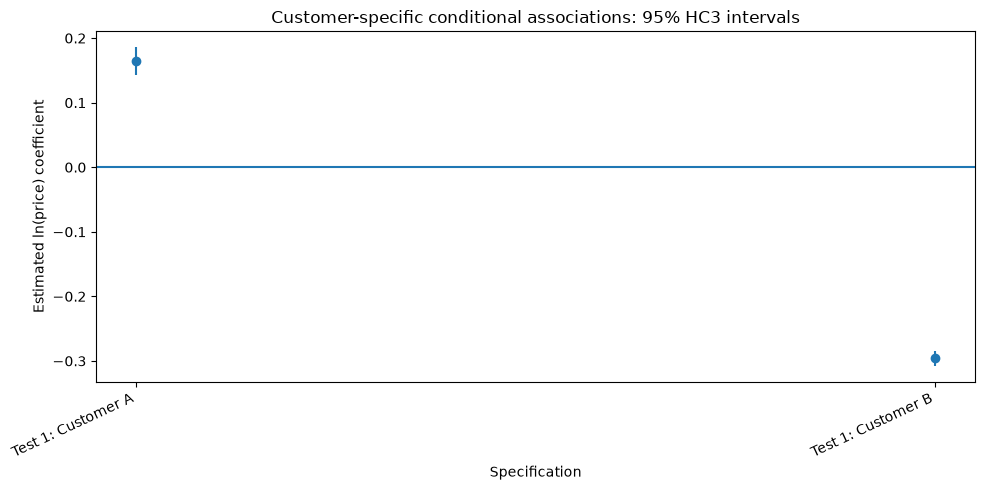

In [188]:
test_model1_results = pd.DataFrame([
    {"Model": "Test 1: Customer A", "Source N": source_A_N, **extract_price(test_model1_A, "ln_P_1")},
    {"Model": "Test 1: Customer B", "Source N": source_B_N, **extract_price(test_model1_B, "ln_P_1")},
])
display(format_pvalues_for_display(test_model1_results))
coefficient_plot(test_model1_results, "Model", "Customer-specific conditional associations: 95% HC3 intervals")

### Test whether the A and B coefficients differ
Different point estimates, overlapping intervals, or significance in only one subgroup do not themselves test equality. Test **H₀: beta_A − beta_B = 0** using the separately fitted coefficients.

Under the independent-observation assumption used by these HC3 fits, the disjoint groups have zero cross-group covariance, so `SE(diff) = sqrt(HC3_SE_A² + HC3_SE_B²)`. Use a two-sided normal approximation and a 95% interval. **Shared train/departure shocks could violate cross-group independence**; HC3 does not address that dependence, so this test is conditional on this assumption, not a definitive structural elasticity comparison. No interactions or new estimator are introduced.

If price is not separately estimable, the standard errors are invalid, or either fit has leverage >=0.99, show the diagnostic problem and do not report a significance conclusion from this approximation.

In [189]:
beta_A = test_model1_A.params["ln_P_1"]
beta_B = test_model1_B.params["ln_P_1"]
beta_A_minus_B = beta_A - beta_B
diff_se = np.hypot(test_model1_A.bse["ln_P_1"], test_model1_B.bse["ln_P_1"])
group_test_usable = (
    np.isfinite([beta_A, beta_B, diff_se]).all() and diff_se > 0
    and test_model1_A_diagnostics["Price separately estimable"]
    and test_model1_B_diagnostics["Price separately estimable"]
    and test_model1_A_diagnostics["Residual degrees of freedom"] > 0
    and test_model1_B_diagnostics["Residual degrees of freedom"] > 0
    and test_model1_A_diagnostics["Cells with leverage >= 0.99"] == 0
    and test_model1_B_diagnostics["Cells with leverage >= 0.99"] == 0)
if group_test_usable:
    diff_z = beta_A_minus_B / diff_se
    diff_p = erfc(abs(diff_z) / sqrt(2))
    critical_z = NormalDist().inv_cdf(0.975)
    group_difference_test = pd.DataFrame([{"Contrast": "beta_A - beta_B",
        "Coefficient difference": beta_A_minus_B, "HC3-based SE of difference": diff_se,
        "z-stat": diff_z, "Two-sided p-value": diff_p,
        "95% CI lower": beta_A_minus_B - critical_z * diff_se,
        "95% CI upper": beta_A_minus_B + critical_z * diff_se}])
    display(format_pvalues_for_display(group_difference_test))
    conclusion = ("Evidence of different conditional price coefficients at the 5% level."
                  if diff_p < 0.05 else "Insufficient evidence of different coefficients at the 5% level; this does not establish equality.")
    display(Markdown(conclusion + " This conclusion assumes independent errors across the A/B cells. "
        "Compare signs and magnitudes as well: a numerically larger negative coefficient means a less negative association."))
else:
    group_difference_test = pd.DataFrame([{"Contrast": "beta_A - beta_B", "Coefficient difference": beta_A_minus_B,
        "HC3-based SE of difference": diff_se, "Status": "Inference withheld: inspect price estimability / HC3 / leverage diagnostics"}])
    display(format_pvalues_for_display(group_difference_test))
    display(Markdown("Report the A/B point estimates descriptively. The diagnostics do not support a reliable HC3-based equality-test conclusion under this specification."))

,Contrast,Coefficient difference,HC3-based SE of difference,Status
0,beta_A - beta_B,0.460552,0.012346,Inference withheld: inspect price estimability...


Report the A/B point estimates descriptively. The diagnostics do not support a reliable HC3-based equality-test conclusion under this specification.

### Test 1A: Customer A/B Without Lead-Time Controls
Fit separate A and B versions of **Reference Model 0** on the same eligible 120-day source sample, retaining exact prices and original semi-aggregated record quantities in the current zero-aggregation case. Subset the existing reference data; do not remove records based on coefficient signs or flags.

Use the reference controls, dropping only `C(Customer_Cat)` because it is constant within each subset. Do not include `C(lead_category)` or another lead-time regressor. The comparison uses the existing category-specific **Model 1** fits with lead controls, not the pooled main coefficient. Interpret differences as a diagnostic of conditional associations. The existing cell-equivalence check indicates whether changing the lead controls is the sole specification difference in this input.

In [190]:
ab_no_lead_A_data = reference_model0_data.loc[reference_model0_data["Customer_Cat"].eq("A")].copy()
ab_no_lead_B_data = reference_model0_data.loc[reference_model0_data["Customer_Cat"].eq("B")].copy()
for category, frame, expected_n in [("A", ab_no_lead_A_data, source_A_N), ("B", ab_no_lead_B_data, source_B_N)]:
    if frame.empty:
        raise ValueError(f"No customer {category} observations for the reference diagnostic.")
    for col in frame.select_dtypes(include="category").columns:
        frame[col] = frame[col].cat.remove_unused_categories()
    assert frame["n_original_records"].sum() == expected_n
    print(category, "eligible source N:", expected_n, "reference regression N:", len(frame),
          "additional aggregation %:", 100 * (expected_n - len(frame)) / expected_n)
ab_reference_controls = " + ".join(term for term in controls_reference_model0.split(" + ")
                                    if term != "C(Customer_Cat)")
ab_reference_formula = "ln_Q_0 ~ ln_P_0 + " + ab_reference_controls
assert "lead_category" not in ab_reference_formula and "lead_days" not in ab_reference_formula
assert "C(Customer_Cat)" not in ab_reference_formula
assert set(controls_by_customer.split(" + ")) - set(ab_reference_controls.split(" + ")) == {"C(lead_category)"}
print(ab_reference_formula)
print("Reference/main regression observations equivalent:", same_regression_cells)

A eligible source N: 32401 reference regression N: 32401 additional aggregation %: 0.0
B eligible source N: 91590 reference regression N: 91590 additional aggregation %: 0.0
ln_Q_0 ~ ln_P_0 + C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway) + C(dept_dow) + C(dept_month)
Reference/main regression observations equivalent: True


In [191]:
ab_no_lead_A = smf.ols(ab_reference_formula, data=ab_no_lead_A_data, missing="raise").fit(cov_type="HC3")
assert int(ab_no_lead_A.nobs) == len(ab_no_lead_A_data)

In [192]:
ab_no_lead_A_diagnostics = model_diagnostics(ab_no_lead_A, "ln_P_0")
display(format_pvalues_for_display(pd.DataFrame([extract_price(ab_no_lead_A, "ln_P_0")], index=["Customer A: reference without lead controls"])))

Design columns                       33
Design rank                          33
Residual degrees of freedom     32368.0
Price separately estimable         True
Maximum leverage               0.008987
Cells with leverage >= 0.99           0
Finite price HC3 SE                True
dtype: object

,Regression N,ln(price) coefficient,HC3 SE,t/z-stat,p-value,95% CI lower,95% CI upper,R-squared,Adjusted R-squared
Customer A: reference without lead controls,32401,0.277995,0.010711,25.954595,< 0.001,0.257003,0.298988,0.071044,0.070126


In [193]:
ab_no_lead_B = smf.ols(ab_reference_formula, data=ab_no_lead_B_data, missing="raise").fit(cov_type="HC3")
assert int(ab_no_lead_B.nobs) == len(ab_no_lead_B_data)

In [194]:
ab_no_lead_B_diagnostics = model_diagnostics(ab_no_lead_B, "ln_P_0")
display(format_pvalues_for_display(pd.DataFrame([extract_price(ab_no_lead_B, "ln_P_0")], index=["Customer B: reference without lead controls"])))

Design columns                      34
Design rank                         34
Residual degrees of freedom    91556.0
Price separately estimable        True
Maximum leverage                   1.0
Cells with leverage >= 0.99          1
Finite price HC3 SE               True
dtype: object

C:\Users\aatmi\AppData\Local\Temp\ipykernel_32656\3065665930.py:33: UserWarning: High leverage or limited residual information may make HC3 inference unreliable.
  warnings.warn("High leverage or limited residual information may make HC3 inference unreliable.")


,Regression N,ln(price) coefficient,HC3 SE,t/z-stat,p-value,95% CI lower,95% CI upper,R-squared,Adjusted R-squared
Customer B: reference without lead controls,91590,-0.26421,0.005181,-50.996734,< 0.001,-0.274364,-0.254056,0.083747,0.083417


#### Compare A/B with and without the five lead controls
The signed change is beta_with − beta_without. Report separate uncertainty intervals and sample sizes for both versions. The existing `MATERIAL_RELATIVE_CHANGE` is an explicit descriptive reporting convention (20% by default), not a hypothesis test; coefficients are not selected or changed by that threshold.

In [195]:
ab_lead_comparison_rows = []
for category, without, with_lead in [("A", ab_no_lead_A, test_model1_A), ("B", ab_no_lead_B, test_model1_B)]:
    s0 = extract_price(without, "ln_P_0")
    s1 = extract_price(with_lead, "ln_P_1")
    ab_lead_comparison_rows.append({"Customer category": category,
        "Reference coefficient (without lead)": s0["ln(price) coefficient"],
        "Main category coefficient (with lead)": s1["ln(price) coefficient"],
        "Coefficient change (with minus without)": s1["ln(price) coefficient"] - s0["ln(price) coefficient"],
        "HC3 SE without lead": s0["HC3 SE"], "HC3 SE with lead": s1["HC3 SE"],
        "95% CI lower without": s0["95% CI lower"], "95% CI upper without": s0["95% CI upper"],
        "95% CI lower with": s1["95% CI lower"], "95% CI upper with": s1["95% CI upper"],
        "p-value without": s0["p-value"], "p-value with": s1["p-value"],
        "N without": s0["Regression N"], "N with": s1["Regression N"],
        "R-squared without": s0["R-squared"], "R-squared with": s1["R-squared"],
        "Adjusted R-squared without": s0["Adjusted R-squared"], "Adjusted R-squared with": s1["Adjusted R-squared"]})
ab_lead_comparison = pd.DataFrame(ab_lead_comparison_rows)
display(format_pvalues_for_display(ab_lead_comparison))

,Customer category,Reference coefficient (without lead),Main category coefficient (with lead),Coefficient change (with minus without),HC3 SE without lead,HC3 SE with lead,95% CI lower without,95% CI upper without,95% CI lower with,95% CI upper with,p-value without,p-value with,N without,N with,R-squared without,R-squared with,Adjusted R-squared without,Adjusted R-squared with
0,A,0.277995,0.164636,-0.113359,0.010711,0.010829,0.257003,0.298988,0.143412,0.185861,< 0.001,< 0.001,32401,32401,0.071044,0.095457,0.070126,0.094451
1,B,-0.264210,-0.295916,-0.031706,0.005181,0.005928,-0.274364,-0.254056,-0.307535,-0.284296,< 0.001,< 0.001,91590,91590,0.083747,0.088907,0.083417,0.088539


In [196]:
ab_pattern_material = []
for row in ab_lead_comparison.to_dict("records"):
    category = row["Customer category"]
    without = row["Reference coefficient (without lead)"]
    with_lead = row["Main category coefficient (with lead)"]
    if not np.isfinite([without, with_lead]).all():
        display(Markdown(f"**Customer {category}:** nonfinite coefficient; inspect the fit before interpreting the sign pattern."))
        continue
    sign_without = "positive" if without > 0 else "negative" if without < 0 else "zero"
    sign_with = "positive" if with_lead > 0 else "negative" if with_lead < 0 else "zero"
    sign_changed = np.sign(without) != np.sign(with_lead)
    relative_shift = abs(with_lead - without) / abs(without) if without != 0 else np.nan
    magnitude_change = abs(with_lead) - abs(without)
    material = sign_changed or (np.isfinite(relative_shift) and relative_shift >= MATERIAL_RELATIVE_CHANGE)
    ab_pattern_material.append(material)
    sign_message = "The sign changed after adding lead controls." if sign_changed else "The sign did not change after adding lead controls."
    material_message = "The shift is material under the stated descriptive rule." if material else "The shift is below the stated descriptive threshold."
    display(Markdown(f"**Customer {category}:** the coefficient was **{sign_without} before lead controls** "
        f"({without:.4f}) and is **{sign_with} with lead controls** ({with_lead:.4f}). "
        + sign_message + f" Signed coefficient change: {with_lead - without:+.4f}; "
        f"change in magnitude: {magnitude_change:+.4f}; relative coefficient shift: {relative_shift:.1%}. "
        + material_message))
if len(ab_pattern_material) == 2:
    display(Markdown("**A/B pattern:** " +
        ("The five lead controls materially alter at least one category estimate under the stated rule."
         if any(ab_pattern_material) else "The five lead controls do not materially alter the category estimates under the stated rule.") +
        " A sign pattern can persist even when coefficient magnitudes change substantially. This is a descriptive comparison, not a causal effect of booking stage."))
if not same_regression_cells:
    display(Markdown("The reference/main grouping checks did not establish equivalent observations, so differences may also reflect grouping rather than controls alone."))
if test_model1_A.params["ln_P_1"] > 0:
    display(Markdown("Customer A retains a **positive conditional association** in the main specification. Pricing endogeneity, omitted demand conditions, or segment-specific pricing behavior are possible explanations, not established findings. We retain the observed sign and unchanged main specification; no A observations or controls are removed to obtain an expected sign."))

**Customer A:** the coefficient was **positive before lead controls** (0.2780) and is **positive with lead controls** (0.1646). The sign did not change after adding lead controls. Signed coefficient change: -0.1134; change in magnitude: -0.1134; relative coefficient shift: 40.8%. The shift is material under the stated descriptive rule.

**Customer B:** the coefficient was **negative before lead controls** (-0.2642) and is **negative with lead controls** (-0.2959). The sign did not change after adding lead controls. Signed coefficient change: -0.0317; change in magnitude: +0.0317; relative coefficient shift: 12.0%. The shift is below the stated descriptive threshold.

**A/B pattern:** The five lead controls materially alter at least one category estimate under the stated rule. A sign pattern can persist even when coefficient magnitudes change substantially. This is a descriptive comparison, not a causal effect of booking stage.

Customer A retains a **positive conditional association** in the main specification. Pricing endogeneity, omitted demand conditions, or segment-specific pricing behavior are possible explanations, not established findings. We retain the observed sign and unchanged main specification; no A observations or controls are removed to obtain an expected sign.

### Test 1B: Customer B Excluding the Rare-Train Observation
First inspect the existing **Customer B main-specification** regression leverage. Align hat values to fitted rows, then map each high-leverage regression observation back to its cleaned source records using the exact main grouping keys. Show the supplied flag alongside price, quantity, and dates before attributing leverage to a rare train.

In the documented zero-aggregation case each fitted observation maps to one cleaned source record. If the data change and a group contains several records, leverage belongs to the regression group; the source display repeats that group's leverage for its component records and shows `n_original_records`. It is not a separate source-row leverage estimate.

In [197]:
b_diagnostic_rows = list(test_model1_B.model.data.row_labels)
assert test_model1_B_data.index.is_unique and len(b_diagnostic_rows) == int(test_model1_B.nobs)
b_leverage_cells = test_model1_B_data.loc[b_diagnostic_rows].copy()
b_leverage_cells["leverage"] = test_model1_B.get_influence().hat_matrix_diag
b_source = df_120.loc[df_120["Customer_Cat"].eq("B")].copy()
if "flag_rare_train" not in b_source:
    raise ValueError("flag_rare_train is missing; no train label will be hard-coded.")
b_source_with_leverage = b_source.merge(
    b_leverage_cells[baseline_keys + ["leverage", "n_original_records"]],
    on=baseline_keys, how="left", validate="many_to_one")
assert len(b_source_with_leverage) == len(b_source)
assert b_source_with_leverage["leverage"].notna().all()
b_high_cells = b_leverage_cells.loc[b_leverage_cells["leverage"] >= 0.99]
b_high_sources = b_source_with_leverage.loc[b_source_with_leverage["leverage"] >= 0.99]
print("Customer B regression observations with leverage >= 0.99:", len(b_high_cells))
print("Train labels among these observations:", b_high_cells["Train_Number_All"].unique().tolist())
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(b_high_sources[["_source_row", "Train_Number_All", "dept_date", "purchase_date",
        "mean_net_ticket_price", "num_seats_total", "lead_days", "lead_category", "flag_rare_train",
        "n_original_records", "leverage"]])
b_flag_true, b_flag_missing = read_boolean_flag(b_source["flag_rare_train"], "flag_rare_train")
high_flag_true, high_flag_missing = read_boolean_flag(b_high_sources["flag_rare_train"], "flag_rare_train")
print("Flagged source records among high-leverage observations:", int(high_flag_true.sum()),
      "out of", len(b_high_sources), "; missing flags:", int(high_flag_missing.sum()))

Customer B regression observations with leverage >= 0.99: 1
Train labels among these observations: ['O']


,_source_row,Train_Number_All,dept_date,purchase_date,mean_net_ticket_price,num_seats_total,lead_days,lead_category,flag_rare_train,n_original_records,leverage
79619,192900,O,2018-12-28,2018-12-20,651.752209,1,8,8-14 days,True,1,1.0


Flagged source records among high-leverage observations: 1 out of 1 ; missing flags: 0


#### Exclude flagged B source records only in this sensitivity sample
Remove every B source record explicitly marked `flag_rare_train == True`, not just the high-leverage records. Missing flags are displayed as a count and retained; unrecognized nonmissing encodings stop the check. Display excluded records before rebuilding the **same Model 1 exact-price construction**, using the same five lead categories and other B controls. The original B model is retained for comparison.

In [198]:
b_excluded_records = b_source.loc[b_flag_true].copy()
print("Customer B eligible source N before exclusion:", len(b_source))
print("Rare-flagged B source records excluded:", len(b_excluded_records))
print("Missing rare flags retained:", int(b_flag_missing.sum()))
with pd.option_context("display.max_rows", None):
    display(b_excluded_records[["_source_row", "Train_Number_All", "dept_date", "purchase_date",
                                "mean_net_ticket_price", "num_seats_total", "flag_rare_train"]])
b_without_rare_source = b_source.loc[~b_flag_true].copy()
if b_without_rare_source.empty:
    raise ValueError("No B source records remain after the requested sensitivity exclusion.")
for col in b_without_rare_source.select_dtypes(include="category").columns:
    b_without_rare_source[col] = b_without_rare_source[col].cat.remove_unused_categories()
assert len(b_without_rare_source) + len(b_excluded_records) == source_B_N

b_without_rare_data = (b_without_rare_source.groupby(baseline_keys, observed=True, dropna=False, sort=False)
    .agg(Q_1=("num_seats_total", "sum"), n_original_records=("_source_row", "size"),
         dept_dow=("dept_dow", "first"), dept_month=("dept_month", "first")).reset_index())
b_without_rare_data["P_1"] = b_without_rare_data["mean_net_ticket_price"]
for col in b_without_rare_data.select_dtypes(include="category").columns:
    b_without_rare_data[col] = b_without_rare_data[col].cat.remove_unused_categories()
assert b_without_rare_data["n_original_records"].sum() == len(b_without_rare_source)
assert np.isclose(b_without_rare_data["Q_1"].sum(), b_without_rare_source["num_seats_total"].sum())
check_positive_cells(b_without_rare_data, "Q_1", "P_1")
b_without_rare_data["ln_Q_1"] = np.log(b_without_rare_data["Q_1"])
b_without_rare_data["ln_P_1"] = np.log(b_without_rare_data["P_1"])
print("Same B main formula:", formula_test1)
print("B sensitivity source N / regression N:", len(b_without_rare_source), len(b_without_rare_data))

Customer B eligible source N before exclusion: 91590
Rare-flagged B source records excluded: 1
Missing rare flags retained: 0


,_source_row,Train_Number_All,dept_date,purchase_date,mean_net_ticket_price,num_seats_total,flag_rare_train
192898,192900,O,2018-12-28,2018-12-20,651.752209,1,True


Same B main formula: ln_Q_1 ~ ln_P_1 + C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway) + C(lead_category) + C(dept_dow) + C(dept_month)
B sensitivity source N / regression N: 91589 91589


In [199]:
b_without_rare_model = smf.ols(formula_test1, data=b_without_rare_data, missing="raise").fit(cov_type="HC3")
assert int(b_without_rare_model.nobs) == len(b_without_rare_data)

In [200]:
b_without_rare_diagnostics = model_diagnostics(b_without_rare_model, "ln_P_1")
b_rare_comparison_rows = []
for label, fitted, diagnostics in [
    ("Test 1: Customer B", test_model1_B, test_model1_B_diagnostics),
    ("Test 1B: Customer B excluding rare train", b_without_rare_model, b_without_rare_diagnostics)]:
    statistics = extract_price(fitted, "ln_P_1")
    b_rare_comparison_rows.append({"Specification": label, **statistics,
        "Maximum leverage": diagnostics["Maximum leverage"],
        "Observations with leverage >= 0.99": diagnostics["Cells with leverage >= 0.99"]})
b_rare_comparison = pd.DataFrame(b_rare_comparison_rows).rename(columns={"Regression N": "N"})
display(format_pvalues_for_display(b_rare_comparison))
b_rare_coefficient_difference = b_without_rare_model.params["ln_P_1"] - test_model1_B.params["ln_P_1"]
display(pd.Series({"Coefficient difference (without rare train minus original B)": b_rare_coefficient_difference}))

Design columns                       37
Design rank                          37
Residual degrees of freedom     91552.0
Price separately estimable         True
Maximum leverage               0.003583
Cells with leverage >= 0.99           0
Finite price HC3 SE                True
dtype: object

,Specification,N,ln(price) coefficient,HC3 SE,t/z-stat,p-value,95% CI lower,95% CI upper,R-squared,Adjusted R-squared,Maximum leverage,Observations with leverage >= 0.99
0,Test 1: Customer B,91590,-0.295916,0.005928,-49.915221,< 0.001,-0.307535,-0.284296,0.088907,0.088539,1.000000,1
1,Test 1B: Customer B excluding rare train,91589,-0.295916,0.005928,-49.915221,< 0.001,-0.307535,-0.284296,0.088896,0.088538,0.003583,0


Coefficient difference (without rare train minus original B)   -2.331468e-15
dtype: float64

#### Interpret rare-train sensitivity without assuming its outcome
Use the flagged-source evidence, the change in high-leverage count and maximum leverage, and the price coefficient together. A stable point estimate does not itself validate the original HC3 uncertainty. The same explicit descriptive materiality convention is used below; there is no sign-driven sample selection and no change to the main B fit.

In [201]:
b_high_before = test_model1_B_diagnostics["Cells with leverage >= 0.99"]
b_high_after = b_without_rare_diagnostics["Cells with leverage >= 0.99"]
b_beta_original = test_model1_B.params["ln_P_1"]
b_beta_restricted = b_without_rare_model.params["ln_P_1"]
b_relative_shift = abs(b_rare_coefficient_difference) / abs(b_beta_original) if b_beta_original != 0 else np.nan
if b_high_before > 0 and b_high_after == 0:
    leverage_description = "The >=0.99 high-leverage condition disappears after the flagged-source exclusion."
elif b_high_after < b_high_before:
    leverage_description = "Fewer observations have leverage >=0.99, but the condition remains."
elif b_high_before == b_high_after == 0:
    leverage_description = "Neither fit has observations with leverage >=0.99."
else:
    leverage_description = "The number of observations with leverage >=0.99 does not decrease."
if not np.isfinite([b_beta_original, b_beta_restricted, b_relative_shift]).all():
    coefficient_description = "A relative point-estimate sensitivity conclusion is unavailable; inspect zero/nonfinite values."
elif np.sign(b_beta_original) != np.sign(b_beta_restricted) or b_relative_shift >= MATERIAL_RELATIVE_CHANGE:
    coefficient_description = "The B point estimate is sensitive under the stated rule; the flagged observations appear influential for that estimate in this check."
else:
    coefficient_description = "The B coefficient is not materially changed under the stated rule. The flagged records do not appear to drive the B point estimate, even if they affect leverage and HC3 uncertainty."
display(Markdown(f"**Customer B:** coefficient {b_beta_original:.4f} to {b_beta_restricted:.4f}; "
    f"difference {b_rare_coefficient_difference:+.4f}, relative shift {b_relative_shift:.1%}. "
    f"High-leverage observations: {b_high_before} to {b_high_after}; maximum leverage "
    f"{test_model1_B_diagnostics['Maximum leverage']:.6f} to {b_without_rare_diagnostics['Maximum leverage']:.6f}. "
    + leverage_description + " " + coefficient_description +
    " This is sensitivity to a predefined flag, not proof of a causal explanation or a reason to replace the main specification."))

**Customer B:** coefficient -0.2959 to -0.2959; difference -0.0000, relative shift 0.0%. High-leverage observations: 1 to 0; maximum leverage 1.000000 to 0.003583. The >=0.99 high-leverage condition disappears after the flagged-source exclusion. The B coefficient is not materially changed under the stated rule. The flagged records do not appear to drive the B point estimate, even if they affect leverage and HC3 uncertainty. This is sensitivity to a predefined flag, not proof of a causal explanation or a reason to replace the main specification.

### Compact Summary: Reference, Main Specification, and Customer Diagnostics
These seven rows distinguish whether the five lead-time controls are included. The rare-train exclusion applies only to its explicitly labeled B sensitivity row. All other sample eligibility rules and exact-price treatment are unchanged. Compare conditional coefficient estimates and uncertainty; a higher R-squared does not prove a better causal or economic model.

In [202]:
customer_diagnostic_rows = []
for label, fitted, price_term, lead_controls, rare_exclusion in [
    ("Reference Model 0", reference_model0, "ln_P_0", "No", "No"),
    ("Model 1", model1, "ln_P_1", "Yes", "No"),
    ("Test 1: Customer A", test_model1_A, "ln_P_1", "Yes", "No"),
    ("Test 1A: Customer A without lead controls", ab_no_lead_A, "ln_P_0", "No", "No"),
    ("Test 1: Customer B", test_model1_B, "ln_P_1", "Yes", "No"),
    ("Test 1A: Customer B without lead controls", ab_no_lead_B, "ln_P_0", "No", "No"),
    ("Test 1B: Customer B excluding rare train", b_without_rare_model, "ln_P_1", "Yes", "Yes")]:
    customer_diagnostic_rows.append({"Specification": label, "Five lead-time controls": lead_controls,
        "Rare-train exclusion": rare_exclusion, **extract_price(fitted, price_term)})
customer_diagnostic_summary = pd.DataFrame(customer_diagnostic_rows).rename(columns={"Regression N": "N"})
display(format_pvalues_for_display(customer_diagnostic_summary[["Specification", "Five lead-time controls", "Rare-train exclusion",
    "ln(price) coefficient", "HC3 SE", "95% CI lower", "95% CI upper", "p-value", "N", "R-squared", "Adjusted R-squared"]]))

,Specification,Five lead-time controls,Rare-train exclusion,ln(price) coefficient,HC3 SE,95% CI lower,95% CI upper,p-value,N,R-squared,Adjusted R-squared
0,Reference Model 0,No,No,-0.206706,0.004721,-0.215959,-0.197453,< 0.001,123991,0.128123,0.127884
1,Model 1,Yes,No,-0.252765,0.005243,-0.263042,-0.242489,< 0.001,123991,0.136150,0.135885
2,Test 1: Customer A,Yes,No,0.164636,0.010829,0.143412,0.185861,< 0.001,32401,0.095457,0.094451
3,Test 1A: Customer A without lead controls,No,No,0.277995,0.010711,0.257003,0.298988,< 0.001,32401,0.071044,0.070126
4,Test 1: Customer B,Yes,No,-0.295916,0.005928,-0.307535,-0.284296,< 0.001,91590,0.088907,0.088539
5,Test 1A: Customer B without lead controls,No,No,-0.264210,0.005181,-0.274364,-0.254056,< 0.001,91590,0.083747,0.083417
6,Test 1B: Customer B excluding rare train,Yes,Yes,-0.295916,0.005928,-0.307535,-0.284296,< 0.001,91589,0.088896,0.088538


## Test 2: Price-Binning / Cell-Aggregation Sensitivity
Keep the same eligible 120-day source records, five lead categories, controls, and HC3 method. Reuse Model 1 as the exact observed price baseline and retain all four **$10, $20, $50, and $100** tests.

Price bins permit observations within the same fixed price interval and otherwise identical Model 1 cell characteristics to combine. For each grouped cell, quantity is the sum of seats and price is the seat-weighted average of actual observed prices, not a midpoint or boundary. The exercise therefore changes both price grouping and the effective cell aggregation / quantity unit. It is interpreted as a price-binning / coarser cell-aggregation sensitivity test rather than a pure price functional-form test. In particular, $50 and $100 bins need not represent small price differences.

Each binned specification cannot have more observations than the exact observed price baseline, although finite bin widths need not be nested. Models with different aggregation levels or quantity units should not be selected or ranked purely by R-squared, adjusted R-squared, AIC, or BIC.

In [203]:
def test_model2_price_cells(source, price_width):
    """Only aggregate; fitting and result extraction are in the next cell."""
    if not np.isfinite(price_width) or price_width <= 0:
        raise ValueError("Price width must be positive and finite.")
    work = source.copy()
    work["price_bin_lower"] = np.floor(work["mean_net_ticket_price"] / price_width) * price_width
    work["_price_times_seats"] = work["mean_net_ticket_price"] * work["num_seats_total"]
    binned = (work.groupby(product_timing_keys + ["price_bin_lower"], observed=True, dropna=False, sort=False)
        .agg(Q_test2=("num_seats_total", "sum"), revenue_like=("_price_times_seats", "sum"),
             n_original_records=("_source_row", "size"), dept_dow=("dept_dow", "first"),
             dept_month=("dept_month", "first"), min_actual_price=("mean_net_ticket_price", "min"),
             max_actual_price=("mean_net_ticket_price", "max")).reset_index())
    binned["P_test2"] = binned["revenue_like"] / binned["Q_test2"]
    binned["price_range"] = binned["max_actual_price"] - binned["min_actual_price"]
    for col in binned.select_dtypes(include="category").columns:
        binned[col] = binned[col].cat.remove_unused_categories()
    assert binned["n_original_records"].sum() == len(source)
    assert np.isclose(binned["Q_test2"].sum(), source["num_seats_total"].sum())
    assert np.isclose(binned["revenue_like"].sum(), work["_price_times_seats"].sum())
    assert (binned["min_actual_price"] >= binned["price_bin_lower"]).all()
    assert (binned["max_actual_price"] < binned["price_bin_lower"] + price_width).all()
    assert (binned["P_test2"] >= binned["min_actual_price"] - 1e-8).all()
    assert (binned["P_test2"] <= binned["max_actual_price"] + 1e-8).all()
    check_positive_cells(binned, "Q_test2", "P_test2")
    binned["ln_Q_test2"] = np.log(binned["Q_test2"])
    binned["ln_P_test2"] = np.log(binned["P_test2"])
    return binned

formula_test2 = "ln_Q_test2 ~ ln_P_test2 + " + controls
print(formula_test2)

ln_Q_test2 ~ ln_P_test2 + C(Train_Number_All) + C(isNormCabin) + C(isReturn) + C(isOneway) + C(Customer_Cat) + C(lead_category) + C(dept_dow) + C(dept_month)


### Fit the Four Price-Bin Widths
Fit the $10/$20/$50/$100 sensitivity specifications. The baseline row reuses the fitted Model 1 with exact observed prices. Retain compact summaries and example cells rather than four large regression summaries. Test 1 continues to use the Model 1 exact observed price construction.

In [204]:
test_model2_rows = [{"Specification": "Model 1 baseline: exact observed price", "Price-bin width": np.nan, "Price grouping": "Exact observed price",
    "Source N": source_N, "Aggregation reduction %": 100 * (source_N - len(model1_data)) / source_N,
    "Difference vs baseline": 0.0, **extract_price(model1, "ln_P_1"), **model1_diagnostics}]
test_model2_examples = {}
for width in [10, 20, 50, 100]:
    price_rule = f"${width} bins"
    print(f"Test 2: {price_rule}; unchanged five lead categories")
    binned_data = test_model2_price_cells(df_120, width)
    assert len(binned_data) <= len(model1_data) <= source_N
    aggregation_diagnostics(binned_data, source_N)
    fitted_binned = smf.ols(formula_test2, data=binned_data, missing="raise").fit(cov_type="HC3")
    assert int(fitted_binned.nobs) == len(binned_data)
    binned_diagnostics = model_diagnostics(fitted_binned, "ln_P_test2")
    test_model2_rows.append({"Specification": f"Test 2: {price_rule}", "Price grouping": price_rule,
        "Price-bin width": width,
        "Source N": source_N, "Aggregation reduction %": 100 * (source_N - len(binned_data)) / source_N,
        "Difference vs baseline": fitted_binned.params["ln_P_test2"] - model1.params["ln_P_1"],
        **extract_price(fitted_binned, "ln_P_test2"), **binned_diagnostics})
    test_model2_examples[width] = binned_data.nlargest(5, "n_original_records").copy()
    del fitted_binned, binned_data
    gc.collect()
test_model2_comparison = pd.DataFrame(test_model2_rows)
assert len(test_model2_comparison) == 5  # Exact-price Model 1 plus four binned fits.
display(format_pvalues_for_display(test_model2_comparison))

Test 2: $10 bins; unchanged five lead categories


Eligible source N                  123991.000000
Regression cells                    87707.000000
Aggregation reduction %                29.263414
% cells with 1 cleaned record          80.954770
% cells with 2 cleaned records         11.118839
% cells with 3+ cleaned records         7.926391
Maximum records per cell               24.000000
dtype: float64

count    87707.000000
mean         1.413696
std          1.280044
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         24.000000
Name: n_original_records, dtype: float64

,All cells,Only cells with >=2 records
0.50,0.000000,1.889152
0.90,1.782512,5.734805
0.95,3.339387,7.051072
0.99,6.961141,8.572303
1.00,9.932795,9.932795


Design columns                      39
Design rank                         39
Residual degrees of freedom    87668.0
Price separately estimable        True
Maximum leverage                   1.0
Cells with leverage >= 0.99          1
Finite price HC3 SE               True
dtype: object

...

count    67216.000000
mean         1.844665
std          2.203819
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         33.000000
Name: n_original_records, dtype: float64

,All cells,Only cells with >=2 records
0.50,0.000000,14.623193
0.90,31.846480,72.069734
0.95,55.914150,83.078248
0.99,87.509446,92.004137
1.00,99.330275,99.330275


Design columns                      39
Design rank                         39
Residual degrees of freedom    67177.0
Price separately estimable        True
Maximum leverage                   1.0
Cells with leverage >= 0.99          1
Finite price HC3 SE               True
dtype: object

C:\Users\aatmi\AppData\Local\Temp\ipykernel_32656\3065665930.py:33: UserWarning: High leverage or limited residual information may make HC3 inference unreliable.
  warnings.warn("High leverage or limited residual information may make HC3 inference unreliable.")


,Specification,Price-bin width,Price grouping,Source N,Aggregation reduction %,Difference vs baseline,Regression N,ln(price) coefficient,HC3 SE,t/z-stat,p-value,95% CI lower,95% CI upper,R-squared,Adjusted R-squared,Design columns,Design rank,Residual degrees of freedom,Price separately estimable,Maximum leverage,Cells with leverage >= 0.99,Finite price HC3 SE
0,Model 1 baseline: exact observed price,NaN,Exact observed price,123991,0.000000,0.000000,123991,-0.252765,0.005243,-48.208127,< 0.001,-0.263042,-0.242489,0.136150,0.135885,39,39,123952.0,True,1.0,1,True
1,Test 2: $10 bins,10.0,$10 bins,123991,29.263414,-0.036671,87707,-0.289436,0.007016,-41.252675,< 0.001,-0.303188,-0.275685,0.216364,0.216025,39,39,87668.0,True,1.0,1,True
2,Test 2: $20 bins,20.0,$20 bins,123991,33.587115,-0.054536,82346,-0.307302,0.007431,-41.353021,< 0.001,-0.321867,-0.292737,0.208676,0.208311,39,39,82307.0,True,1.0,1,True
3,Test 2: $50 bins,50.0,$50 bins,123991,40.686824,-0.073630,73543,-0.326396,0.007999,-40.802847,< 0.001,-0.342074,-0.310717,0.204563,0.204152,39,39,73504.0,True,1.0,1,True
4,Test 2: $100 bins,100.0,$100 bins,123991,45.789614,-0.051394,67216,-0.304159,0.008415,-36.145782,< 0.001,-0.320652,-0.287667,0.203625,0.203174,39,39,67177.0,True,1.0,1,True


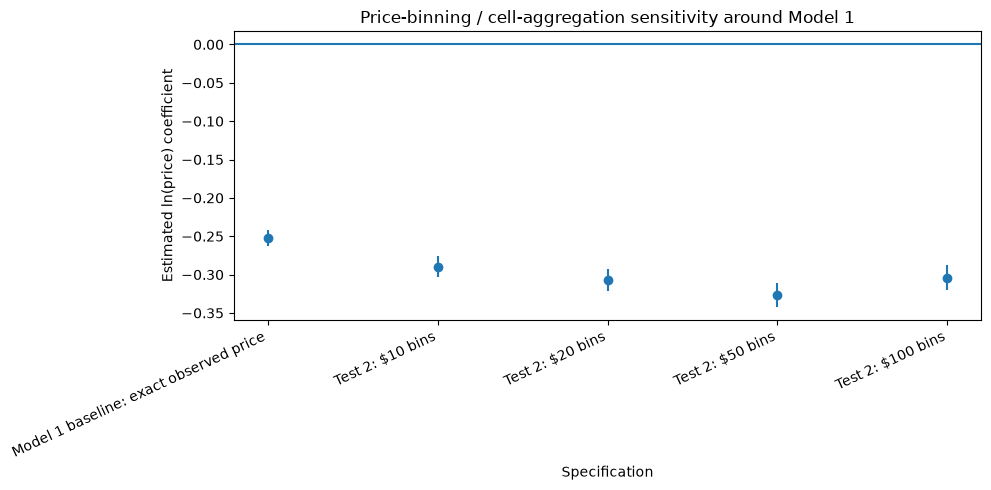

min    -0.326396
max    -0.252765
mean   -0.296012
std     0.027525
Name: Across baseline and four sensitivity fits; std uses ddof=1, dtype: float64

Example cells: $10 price bins


,dept_date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,lead_category,price_bin_lower,Q_test2,P_test2,n_original_records,min_actual_price,max_actual_price,price_range
31701,2019-04-04,M,1,0,0,B,>30 days,100.0,49,105.806845,24,100.382178,109.807349,9.425171
28311,2019-03-11,B,1,1,0,B,>30 days,110.0,88,115.507978,22,111.323417,118.746057,7.422639
31630,2019-03-07,B,1,1,0,B,>30 days,80.0,74,84.822793,22,83.106070,87.147492,4.041422
27798,2019-03-29,E,1,0,0,B,>30 days,80.0,102,85.037197,21,83.014995,86.268785,3.253790
31890,2019-02-28,B,1,1,0,B,>30 days,80.0,65,85.882722,21,83.399103,89.556815,6.157712


Example cells: $20 price bins


,dept_date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,lead_category,price_bin_lower,Q_test2,P_test2,n_original_records,min_actual_price,max_actual_price,price_range
30077,2019-03-07,B,1,1,0,B,>30 days,80.0,79,85.552894,24,83.106070,96.673848,13.567778
30143,2019-04-04,M,1,0,0,B,>30 days,100.0,49,105.806845,24,100.382178,109.807349,9.425171
26895,2019-03-11,B,1,1,0,B,>30 days,100.0,92,114.881103,23,101.089863,118.746057,17.656194
30320,2019-02-28,B,1,1,0,B,>30 days,80.0,72,86.977532,23,83.399103,99.643301,16.244199
30855,2019-02-27,E,1,0,0,B,>30 days,80.0,86,85.758650,23,83.333078,92.223757,8.890678


Example cells: $50 price bins


,dept_date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,lead_category,price_bin_lower,Q_test2,P_test2,n_original_records,min_actual_price,max_actual_price,price_range
24056,2019-03-04,B,1,1,0,B,>30 days,100.0,107,116.950469,27,102.268831,148.171480,45.902649
23721,2019-02-17,G,1,1,0,B,>30 days,100.0,52,133.608693,26,113.458233,149.434141,35.975908
23816,2019-02-28,H,1,0,0,B,>30 days,100.0,63,114.911713,26,107.138546,138.256586,31.118040
24370,2019-03-11,B,1,1,0,B,>30 days,100.0,97,116.560298,26,101.089863,148.313335,47.223472
27291,2019-03-25,B,1,1,0,B,>30 days,100.0,90,120.386984,26,103.983421,148.641764,44.658342


Example cells: $100 price bins


,dept_date,Train_Number_All,isNormCabin,isReturn,isOneway,Customer_Cat,lead_category,price_bin_lower,Q_test2,P_test2,n_original_records,min_actual_price,max_actual_price,price_range
25117,2019-03-25,B,1,1,0,B,>30 days,100.0,112,134.721134,33,103.983421,198.573154,94.589732
22331,2019-04-08,B,1,1,0,B,>30 days,100.0,95,146.983599,29,110.949300,198.132566,87.183266
22940,2018-12-11,J,1,0,0,B,>30 days,100.0,113,142.188407,29,121.165081,185.299050,64.133969
23073,2019-04-07,B,1,1,0,B,>30 days,100.0,95,130.730663,29,103.054811,198.816729,95.761918
22435,2019-06-14,E,1,0,0,B,>30 days,100.0,119,131.054013,28,109.598171,199.335959,89.737788


In [205]:
coefficient_plot(test_model2_comparison, "Specification", "Price-binning / cell-aggregation sensitivity around Model 1")
display(test_model2_comparison["ln(price) coefficient"].agg(["min", "max", "mean", "std"])
        .rename("Across baseline and four sensitivity fits; std uses ddof=1"))
for width, examples in test_model2_examples.items():
    print(f"Example cells: ${width} price bins")
    display(examples[product_timing_keys + ["price_bin_lower", "Q_test2", "P_test2", "n_original_records",
                                      "min_actual_price", "max_actual_price", "price_range"]])

### Interpret price-binning / cell-aggregation sensitivity
Compare sign, magnitude, uncertainty, source-record multiplicities, and regression N. Adding price bins changes the quantity unit when records combine. The next cell describes observed coefficient variation; it is not a formal test of differences between estimates from overlapping source data. R-squared, AIC, or BIC should not be used alone to rank these different observation units or select a preferred bin.

In [206]:
price_sensitivity_betas = test_model2_comparison["ln(price) coefficient"].to_numpy()
if np.isfinite(price_sensitivity_betas).all():
    same_sign = bool((np.sign(price_sensitivity_betas) == np.sign(model1.params["ln_P_1"])).all())
    largest_difference = float(np.max(np.abs(price_sensitivity_betas - model1.params["ln_P_1"])))
    sign_description = "The sign is unchanged across these specifications." if same_sign else "The sign changes across these specifications."
    display(Markdown(f"{sign_description} Coefficients range from {price_sensitivity_betas.min():.4f} "
        f"to {price_sensitivity_betas.max():.4f}; the largest absolute deviation from the baseline "
        f"is {largest_difference:.4f} coefficient points. Judge whether this change is economically material "
        "alongside HC3 uncertainty, leverage, and how much aggregation occurs. Model 1 with exact observed prices remains the prespecified baseline."))
else:
    display(Markdown("At least one coefficient is nonfinite. Review estimability diagnostics before interpreting sensitivity across all specifications."))

The sign is unchanged across these specifications. Coefficients range from -0.3264 to -0.2528; the largest absolute deviation from the baseline is 0.0736 coefficient points. Judge whether this change is economically material alongside HC3 uncertainty, leverage, and how much aggregation occurs. Model 1 with exact observed prices remains the prespecified baseline.

## Results Overview and Limitations
The final table collects Reference Model 0, Model 1, the Test 1 customer-specific estimates, and the four Test 2 price-bin sensitivity fits. Customer estimates use different source subsets. For every row, aggregation reduction is relative to that row's own eligible source N. R-squared comparisons across aggregation definitions or customer subsets are not a model-selection criterion.

In [207]:
final_rows = [reference_model0_result.copy(), model1_result.copy()]
for label, fitted, group_source_n in [("Test 1: Customer A", test_model1_A, source_A_N),
                                     ("Test 1: Customer B", test_model1_B, source_B_N)]:
    final_rows.append({"Model": label, "Source N": group_source_n,
        "Aggregation reduction %": 100 * (group_source_n - fitted.nobs) / group_source_n,
        **extract_price(fitted, "ln_P_1")})
for row in test_model2_comparison.iloc[1:].to_dict("records"):
    final_rows.append({"Model": row["Specification"], **{key: row[key] for key in model1_result if key != "Model"}})
final_comparison = pd.DataFrame(final_rows)
display(format_pvalues_for_display(final_comparison))

,Model,Source N,Aggregation reduction %,Regression N,ln(price) coefficient,HC3 SE,t/z-stat,p-value,95% CI lower,95% CI upper,R-squared,Adjusted R-squared
0,Reference Model 0: reference without lead-time...,123991,0.000000,123991,-0.206706,0.004721,-43.784165,< 0.001,-0.215959,-0.197453,0.128123,0.127884
1,"Model 1: Main specification, exact observed price",123991,0.000000,123991,-0.252765,0.005243,-48.208127,< 0.001,-0.263042,-0.242489,0.136150,0.135885
2,Test 1: Customer A,32401,0.000000,32401,0.164636,0.010829,15.203287,< 0.001,0.143412,0.185861,0.095457,0.094451
3,Test 1: Customer B,91590,0.000000,91590,-0.295916,0.005928,-49.915221,< 0.001,-0.307535,-0.284296,0.088907,0.088539
4,Test 2: $10 bins,123991,29.263414,87707,-0.289436,0.007016,-41.252675,< 0.001,-0.303188,-0.275685,0.216364,0.216025
5,Test 2: $20 bins,123991,33.587115,82346,-0.307302,0.007431,-41.353021,< 0.001,-0.321867,-0.292737,0.208676,0.208311
6,Test 2: $50 bins,123991,40.686824,73543,-0.326396,0.007999,-40.802847,< 0.001,-0.342074,-0.310717,0.204563,0.204152
7,Test 2: $100 bins,123991,45.789614,67216,-0.304159,0.008415,-36.145782,< 0.001,-0.320652,-0.287667,0.203625,0.203174


### Interpretation Notes
1. **Sample:** all specifications start from the supplied 120-day analysis flag. No quality flag is excluded from Reference Model 0, official Model 1, Test 1, Test 1A, or Test 2. Rare-train exclusions occur only in the explicitly labeled Model 1 add-on sensitivity and Test 1B; the official fits remain intact. Any invalid-input exclusions are displayed before modelling.
2. **Reference:** Reference Model 0 uses the 120-day sample, exact observed prices, and no lead-time regression controls. Its strict verification combinations are unique in the current data, so it also produces no additional aggregation. Upstream cleaning may already have aggregated raw records.
3. **Model 1:** strict grouping was attempted using identical observed price and relevant record characteristics, but all combinations are unique. Model 1 therefore retains the original semi-aggregated observations and their exact observed price variation. Test 1 uses customer subsets of these same observations. Reference Model 0 additionally requires identical purchase dates.
4. **Unequal booking windows:** the five lead categories have different widths, especially >30 days. Lead-category controls absorb common level differences but do not make observed booking coverage identical across departures. Only observed sales records are included; no zero-sales opportunities are constructed.
5. **Calendar and controls:** cleaned year-month effects distinguish, for example, June 2018 from June 2019. Identical control families do not imply identical fitted nuisance effects in the A/B regressions. Sparse categories or other collinearity can affect estimability and HC3 inference. Return and one-way indicators are retained as supplied and are not assumed to be logical complements.
6. **Customer comparison:** the Test 1 A/B coefficient-difference calculation assumes independent errors across disjoint customer observations. Common train/departure shocks can invalidate that assumption. Failure to reject equality is not evidence that the coefficients are identical.
7. **Price-grouping sensitivity:** Test 2 replaces the baseline exact observed price key with $10/$20/$50/$100 bins while retaining the five lead categories. Records within the same fixed price interval and otherwise identical cell characteristics may combine. Quantity is summed and price is the seat-weighted average of actual observed prices, changing both price grouping and the effective quantity unit. These fits should not be ranked solely by fit statistics.
8. **Causality:** aggregation and HC3 do not solve price endogeneity, capacity constraints, or dynamic pricing. Higher expected demand may raise prices. Report fitted coefficients as conditional associations unless additional identification evidence supports a causal interpretation.

After running, explain how adding lead-time controls changes the reference result, whether the Test 1 customer associations differ under the stated assumptions, how the rare-train sensitivities affect leverage and coefficients, and how Test 2 changes the prespecified baseline. Discuss magnitude and uncertainty together; do not select the largest R-squared as the "best" model.